# Signature Forgery Detection using Machine Learning
### Feature Engineering, Regularization and Ensemble-Based Classification on the CEDAR Database

**Course:** CSE2032 Machine Learning, BML Munjal University

| Team member | Roll No. | Main responsibility |
|---|---|---|
| Nancy Yadav | 240710 | Pre-processing, EDA, stroke-thickness & aspect-ratio features, Logistic Regression with L1/L2 |
| Purva Joshi | 240727 | Curvature, pixel-density & projection features, feature selection, SVM & KNN, GridSearchCV, FAR/FRR/ROC-AUC |
| Jiya Joshi | 240954 | Writer-wise split & cross-validation, Decision Tree (pruning), Random Forest, Boosting, final comparison |

**Goal.** Given a scanned signature, decide whether it is **Genuine (0)** or **Forged (1)** using hand-crafted
features (stroke thickness, curvature, aspect ratio, pixel-density distribution, projection profiles, ...) and
classical machine-learning models.

**Notebook map**
1. Setup
2. Dataset and Exploratory Data Analysis (EDA) of the images
3. Pre-processing
4. Feature derivation
5. EDA of the features (the key finding that drives the method)
6. Writer-wise train/test split
7. Experiment 1: absolute features (no reference signatures)
8. Experiment 2: writer-normalised features (reference-based, final system)
9. Regularization (Lasso / Ridge)
10. Hyper-parameter tuning of all models + ensembles
11. Performance analysis on unseen writers
12. Decision threshold for a low False Acceptance Rate
13. Feature contributions, effect of the number of references, failure analysis
14. Saving the final model for the demo app
15. Summary

## 1. Setup

In [1]:
import os
import sys
import time
import json
import shutil
import warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT) + os.pathsep + os.environ.get("PYTHONPATH", "")  # for parallel workers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import joblib
from joblib import Parallel, delayed
from IPython.display import display

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_curve, confusion_matrix
from sklearn.base import clone
import sklearn, skimage

from src import config
from src.data import build_index, load_gray
from src.features import (extract_record, extract_features, FEATURE_GROUPS, FEATURE_NAMES,
                          MODEL_FEATURES, INTENSITY_FEATURES)
from src.reference import (select_references, pooled_within_writer_std,
                           build_reference_dataset, DIST_FEATURES)
from src.evaluation import (compute_metrics, equal_error_rate, threshold_for_far,
                            far_frr, get_scores)
from src.modeling import (model_zoo, tune_all, finalize, add_voting, cv_table,
                          cv_scores_for, test_table, SCORING)
from src.analysis import image_path, eta_squared, cohens_d, correlation_filter, param_curve, same_value
from src import plotting as P

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
P.set_style()
np.random.seed(config.RANDOM_STATE)

# Features are cached in outputs/features_raw.csv; set True to re-extract from the 2,640 images (~1-2 min)
RECOMPUTE_FEATURES = not config.FEATURES_CSV.exists()
# FAST_MODE = True uses smaller hyper-parameter grids (~3 min instead of ~15 min) for a quick demo run
FAST_MODE = os.environ.get("SIG_FAST", "0") == "1"
print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__,
      "| scikit-image", skimage.__version__, "| pandas", pd.__version__)
print("Project root:", ROOT)

Python 3.11.9 | scikit-learn 1.9.1 | scikit-image 0.26.0 | pandas 3.1.1
Project root: C:\Users\nancy\OneDrive\Desktop\ML_Project


## 2. Dataset and EDA of the raw images

**CEDAR signature database** (Center of Excellence for Document Analysis and Recognition, University at Buffalo):
55 writers, each wrote **24 genuine** signatures; skilled forgers imitated every writer **24 times**.
Total 2,640 grey-scale scans (300 dpi). Files: `full_org/original_<writer>_<n>.png` and
`full_forg/forgeries_<writer>_<n>.png`.

In [2]:
index = build_index()
print("Total images:", len(index))
display(index.head())

summary = pd.DataFrame({
    "Images": index.groupby("label").size().rename({0: "Genuine", 1: "Forged"}),
    "Writers": index.groupby("label")["writer"].nunique().rename({0: "Genuine", 1: "Forged"}),
})
display(summary)
per_writer = index.groupby(["writer", "label"]).size().unstack()
print("Images per writer and class -> min:", per_writer.min().to_dict(), " max:", per_writer.max().to_dict())

Total images: 2640


,path,file,writer,sample,label
0,C:\Users\nancy\OneDrive\Desktop\ML_Project\dat...,original_1_1.png,1,1,0
1,C:\Users\nancy\OneDrive\Desktop\ML_Project\dat...,original_1_2.png,1,2,0
2,C:\Users\nancy\OneDrive\Desktop\ML_Project\dat...,original_1_3.png,1,3,0
3,C:\Users\nancy\OneDrive\Desktop\ML_Project\dat...,original_1_4.png,1,4,0
4,C:\Users\nancy\OneDrive\Desktop\ML_Project\dat...,original_1_5.png,1,5,0


,Images,Writers
label,,
Genuine,1320,55
Forged,1320,55


Images per writer and class -> min: {0: 24, 1: 24}  max: {0: 24, 1: 24}


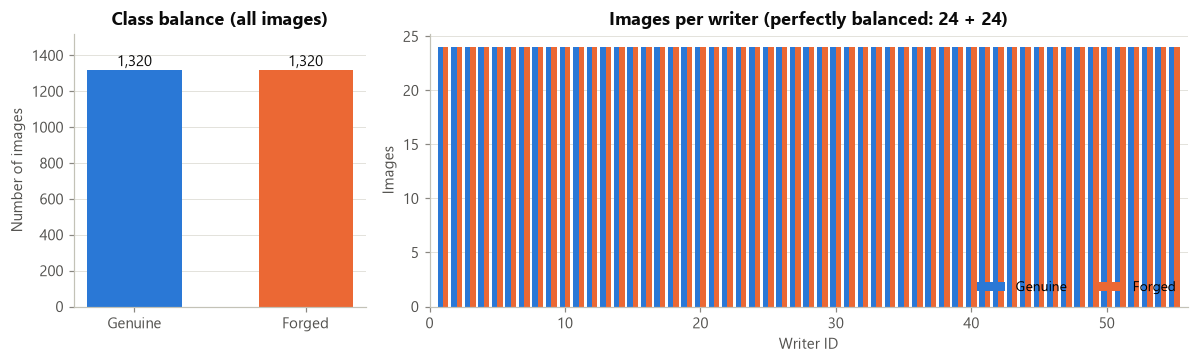

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 2.6]})
counts = index["label"].value_counts().sort_index()
axes[0].bar(["Genuine", "Forged"], counts.values, color=[P.GENUINE, P.FORGED], width=0.55)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, f"{v:,}", ha="center", color=P.INK, fontsize=10)
axes[0].set_title("Class balance (all images)")
axes[0].set_ylabel("Number of images")
axes[0].set_ylim(0, counts.max() * 1.15)
axes[0].grid(axis="x", visible=False)

w = per_writer.index.to_numpy()
axes[1].bar(w - 0.2, per_writer[0], width=0.4, color=P.GENUINE, label="Genuine")
axes[1].bar(w + 0.2, per_writer[1], width=0.4, color=P.FORGED, label="Forged")
axes[1].set_title("Images per writer (perfectly balanced: 24 + 24)")
axes[1].set_xlabel("Writer ID")
axes[1].set_ylabel("Images")
axes[1].set_xlim(0, 56)
axes[1].legend(loc="lower right", ncol=2)
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
P.save(fig, "fig01_class_balance")
plt.show()

### Visual differences between genuine signatures and skilled forgeries

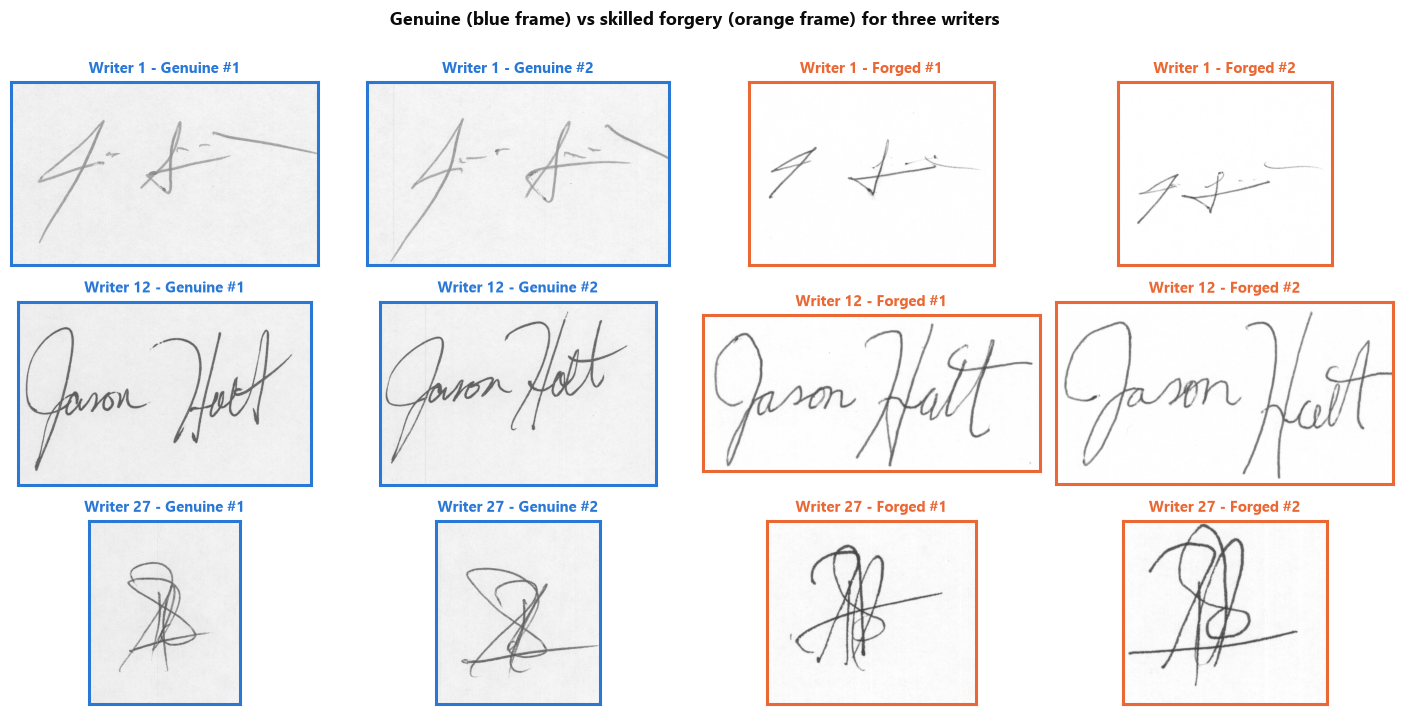

In [4]:
demo_writers = [1, 12, 27]
fig, axes = plt.subplots(len(demo_writers), 4, figsize=(13, 2.15 * len(demo_writers)))
for r, wr in enumerate(demo_writers):
    g = index[(index.writer == wr) & (index.label == 0)].iloc[[0, 1]]
    f_ = index[(index.writer == wr) & (index.label == 1)].iloc[[0, 1]]
    for c, (_, row) in enumerate(pd.concat([g, f_]).iterrows()):
        ax = axes[r, c]
        ax.imshow(load_gray(row.path), cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(True); s.set_color(P.GENUINE if row.label == 0 else P.FORGED); s.set_linewidth(2)
        ax.set_title(f"Writer {wr} - {'Genuine' if row.label == 0 else 'Forged'} #{row['sample']}",
                     fontsize=9.5, color=P.GENUINE if row.label == 0 else P.FORGED)
fig.suptitle("Genuine (blue frame) vs skilled forgery (orange frame) for three writers", y=1.0,
             fontsize=12, fontweight="bold", color=P.INK)
fig.tight_layout()
P.save(fig, "fig02_sample_signatures")
plt.show()

## 3. Feature extraction over the whole dataset (with raw-image statistics for EDA)

`extract_record()` reads each image once and returns:
* raw-image statistics for data-quality EDA (size, paper brightness, MD5 hash for duplicates), and
* the 51 hand-crafted features (Section 4 explains them).

The 2,640 images are processed in parallel on all CPU cores and cached in `outputs/features_raw.csv`.

In [5]:
if config.FEATURES_CSV.exists() and not RECOMPUTE_FEATURES:
    records = pd.read_csv(config.FEATURES_CSV)
    print("Loaded cached features:", records.shape)
else:
    t0 = time.time()
    recs = Parallel(n_jobs=-1, batch_size=8)(delayed(extract_record)(p) for p in index["path"])
    records = pd.concat([index.drop(columns="path").reset_index(drop=True), pd.DataFrame(recs)], axis=1)
    records.to_csv(config.FEATURES_CSV, index=False)
    print(f"Extracted features for {len(records)} images in {time.time() - t0:.1f}s")
records["path"] = records.apply(image_path, axis=1)
F_ALL = FEATURE_NAMES          # 51 derived features
F = MODEL_FEATURES             # 49 features used by the models (grey-level features excluded, see 3.1)
print("Derived features:", len(F_ALL), "| used by the models:", len(F), "| excluded:", INTENSITY_FEATURES)

Extracted features for 2640 images in 56.4s
Derived features: 51 | used by the models: 49 | excluded: ['pressure_contrast', 'ink_gray_std']


### 3.1 Data-quality checks

In [6]:
failed = records["error"].notna() & (records["error"].astype(str).str.len() > 0)
print("Images that failed to process:", int(failed.sum()))
if failed.any():
    display(records.loc[failed, ["file", "error"]])
    records = records.loc[~failed].reset_index(drop=True)      # excluded from all analysis
dups = records[records.duplicated("md5", keep=False)].sort_values("md5")
print("Missing values in features    :", int(records[F].isna().sum().sum()))
print("Exact duplicate files (MD5)   :", len(dups))
if len(dups):
    display(dups[["file", "writer", "label", "md5"]].head(10))

quality = records.groupby("label")[["img_width", "img_height", "background_level",
                                      "otsu_threshold", "noise_pixels_removed"]].describe().T
quality.columns = ["Genuine", "Forged"]
quality = quality.loc[(slice(None), ["mean", "std", "min", "max"]), :]
quality.to_csv(config.TABLE_DIR / "image_quality_summary.csv")
display(quality)

Images that failed to process: 0
Missing values in features    : 0
Exact duplicate files (MD5)   : 0


Genuine   Forged
img_width            mean 535.7265 551.9530
                     std  100.9297  91.9924
                     min  264.0000 270.0000
                     max  672.0000 888.0000
img_height           mean 355.7311 345.2220
                     std   87.1543  82.7253
                     min  145.0000 156.0000
                     max  576.0000 816.0000
background_level     mean 239.7682 253.4962
                     std    2.3556   1.5951
                     min  234.0000 249.0000
                     max  245.0000 255.0000
otsu_threshold       mean 154.6470 157.7220
                     std    5.7018   6.1060
                     min  141.0000 143.0000
                     max  169.0000 179.0000
noise_pixels_removed mean  25.4985  24.0758
                     std   34.0814  33.7368
                     min    0.0000   0.0000
                     max  327.0000 287.0000

### 3.2 A hidden shortcut: the two classes were scanned differently
The paper (background) brightness of every scan is its median grey level. If genuine and forged signatures
had been scanned in the same way, the two histograms below would overlap.

In [7]:
bg_g = records.loc[records.label == 0, "background_level"]
bg_f = records.loc[records.label == 1, "background_level"]
thr_bg = (bg_g.max() + bg_f.min()) / 2
acc_bg = ((records.background_level > thr_bg).astype(int) == records.label).mean()
print(f"Paper brightness - genuine: {bg_g.min():.0f}-{bg_g.max():.0f} (median {bg_g.median():.0f}), "
      f"forged: {bg_f.min():.0f}-{bg_f.max():.0f} (median {bg_f.median():.0f})")
print(f"The rule 'paper brightness > {thr_bg:.0f}  ->  forged' alone is {acc_bg:.1%} accurate on all 2,640 images!")
print("Otsu threshold after intensity normalisation (genuine vs forged):",
      records.groupby("label")["otsu_threshold"].mean().round(1).tolist())

Paper brightness - genuine: 234-245 (median 239), forged: 249-255 (median 254)
The rule 'paper brightness > 247  ->  forged' alone is 100.0% accurate on all 2,640 images!
Otsu threshold after intensity normalisation (genuine vs forged): [154.6, 157.7]


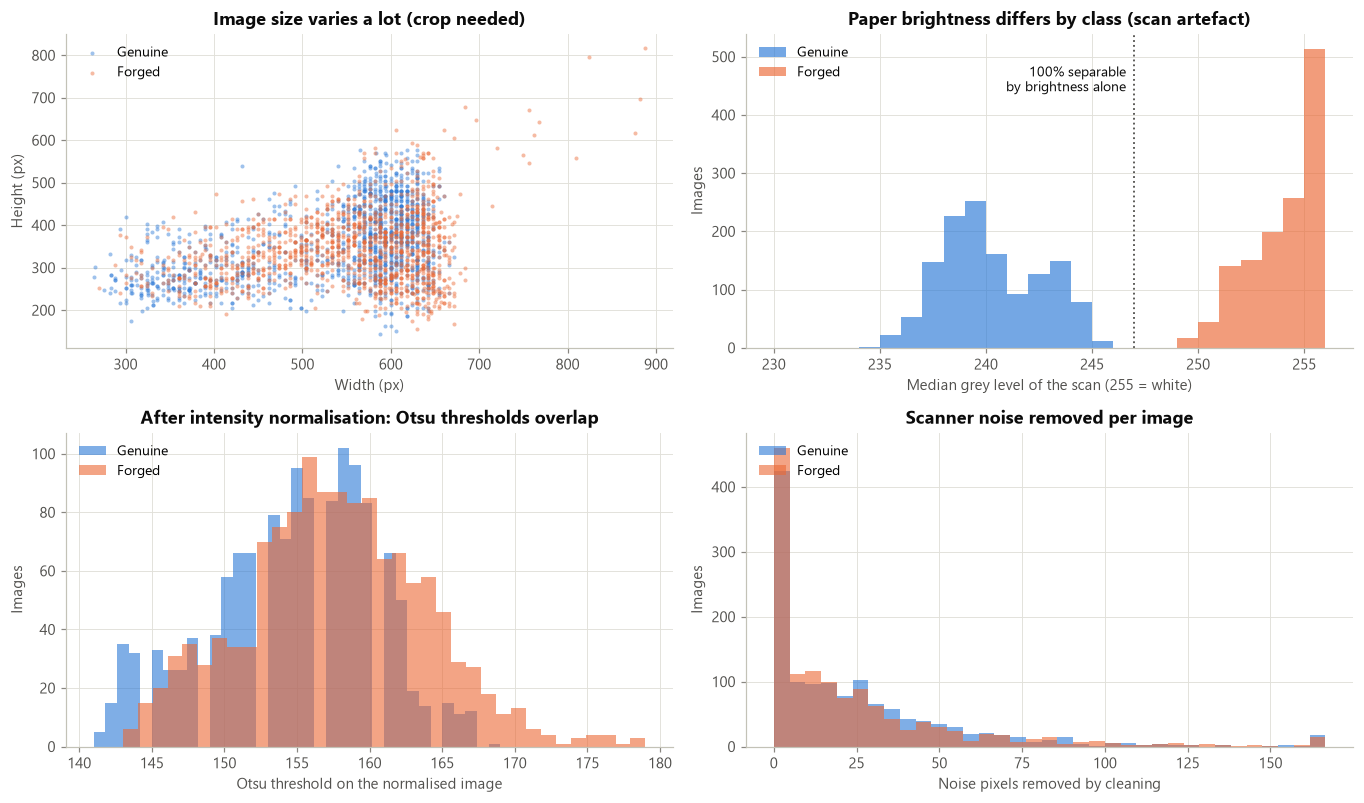

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.4))
for lab, name in ((0, "Genuine"), (1, "Forged")):
    sub = records[records.label == lab]
    axes[0, 0].scatter(sub.img_width, sub.img_height, s=7, alpha=0.45, color=P.CLASS_COLORS[lab], label=name,
                       linewidths=0)
    axes[0, 1].hist(sub.background_level, bins=np.arange(230, 257, 1), alpha=0.65, color=P.CLASS_COLORS[lab],
                    label=name)
    axes[1, 0].hist(sub.otsu_threshold, bins=35, alpha=0.6, color=P.CLASS_COLORS[lab], label=name)
    axes[1, 1].hist(sub.noise_pixels_removed.clip(upper=records.noise_pixels_removed.quantile(0.99)), bins=35,
                    alpha=0.6, color=P.CLASS_COLORS[lab], label=name)
axes[0, 1].axvline(thr_bg, color=P.INK_2, ls=":", lw=1.2)
axes[0, 1].text(thr_bg - 0.4, axes[0, 1].get_ylim()[1] * 0.9, f"{acc_bg:.0%} separable\nby brightness alone",
                ha="right", va="top", fontsize=9, color=P.INK)
axes[0, 0].set(title="Image size varies a lot (crop needed)", xlabel="Width (px)", ylabel="Height (px)")
axes[0, 1].set(title="Paper brightness differs by class (scan artefact)",
               xlabel="Median grey level of the scan (255 = white)", ylabel="Images")
axes[1, 0].set(title="After intensity normalisation: Otsu thresholds overlap",
               xlabel="Otsu threshold on the normalised image", ylabel="Images")
axes[1, 1].set(title="Scanner noise removed per image", xlabel="Noise pixels removed by cleaning",
               ylabel="Images")
for ax in axes.ravel():
    ax.legend(loc="upper left" if ax is not axes[0, 1] else "upper left")
fig.tight_layout()
P.save(fig, "fig03_image_properties")
plt.show()

**This is the most important data issue in CEDAR.** All genuine scans have a greyish paper background
while the forgeries were scanned brighter, so *paper brightness alone separates the classes perfectly*.
That is information about the scanning session, not about the signature: a model that uses raw grey levels
(for example a CNN on raw pixels, or a "pen pressure" feature computed from grey values) can reach very high
accuracy on CEDAR for the wrong reason and would fail on real cheques. We therefore
1. **normalise the intensity** of every image (paper -> 255, darkest ink -> 0) before thresholding, which
   makes the Otsu thresholds of both classes comparable (bottom-left), and
2. compute the two grey-level features (`pressure_contrast`, `ink_gray_std`) only for analysis and
   **exclude them from all models**; pen pressure is represented through stroke thickness, which is measured
   on the binary image.

**Data issues found by EDA and how they are handled**

| Issue | Evidence | Handling |
|---|---|---|
| Genuine and forged scans have different paper brightness | background histogram (100 % separable) | intensity normalisation; grey-level features excluded from the models |
| Different image sizes and blank margins | width/height scatter | crop to the ink bounding box; ratio-type features; resize to a fixed canvas for projection profiles |
| Scanner noise (isolated dark specks) | pixels removed by cleaning | 3x3 median filter + removal of connected components < 30 px |
| Writer identity dominates the features | Section 5 (variance decomposition) | writer-normalised features (Experiment 2) |
| No missing values, no corrupt files, no duplicates | checks above | nothing to impute or remove |

The classes are perfectly balanced (1,320 vs 1,320; 24 + 24 per writer), so no re-sampling is needed.

### 3.3 Pre-processing, step by step

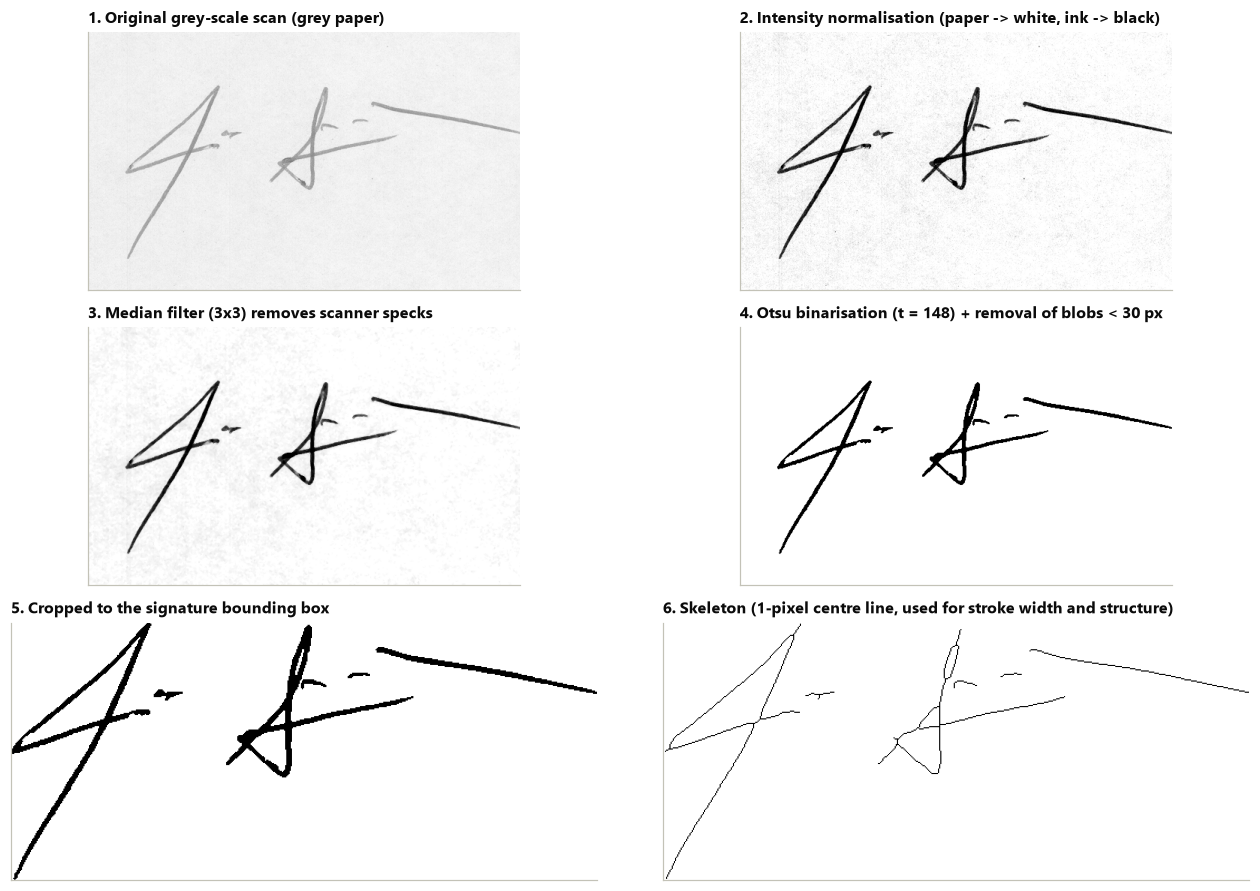

In [9]:
row = records[(records.writer == demo_writers[0]) & (records.label == 0)].iloc[0]
gray = load_gray(row.path)
feats_demo, pp = extract_features(gray, return_intermediate=True)
steps = [
    ("1. Original grey-scale scan (grey paper)", gray),
    ("2. Intensity normalisation (paper -> white, ink -> black)", pp["normalized"]),
    ("3. Median filter (3x3) removes scanner specks", pp["smooth"]),
    (f"4. Otsu binarisation (t = {pp['threshold']:.0f}) + removal of blobs < 30 px", ~pp["binary"]),
    ("5. Cropped to the signature bounding box", ~pp["ink"]),
    ("6. Skeleton (1-pixel centre line, used for stroke width and structure)", ~pp["skeleton"]),
]
fig, axes = plt.subplots(3, 2, figsize=(12, 8.2))
for ax, (title, img) in zip(axes.ravel(), steps):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255 if img.dtype != bool else 1)
    ax.set_title(title, loc="left", fontsize=10.5)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.tight_layout()
P.save(fig, "fig04_preprocessing_steps")
plt.show()

## 4. Feature derivation (51 features in 5 groups, 49 used by the models)

Raw pixels are not used: a 2,640-image dataset is far too small to learn from ~500,000 pixels per image,
and pixel values change with position and size. Instead we measure properties that **forensic document
examiners** look at. A forger copies the *shape* of a signature but writes **slowly and carefully**, which
changes pen pressure, stroke thickness, smoothness (tremor) and proportions.

| Group | Features | Why it can reveal a forgery |
|---|---|---|
| **Stroke thickness & pressure** | mean / std / 95th-percentile stroke width (distance transform on the skeleton); *pressure contrast and ink grey-level spread (EDA only - excluded from the models, see 3.2)* | slow, careful copying changes pen pressure and pen speed, so strokes become thicker or thinner and less uniform |
| **Size & shape** | height, width, **aspect ratio**, ink area, ink density, solidity, eccentricity, principal-axis angle, centroid (x, y), Hu moments 1-2 | forgers rarely reproduce overall proportions, slant and size exactly |
| **Curvature & stroke structure** | mean / std turning angle along the outline, sharp-turn ratio, **tremor index**, stroke-direction histogram (0/45/90/135 deg), skeleton length, end points, junctions, connected components, loops | hesitation creates jerky, tremulous strokes, extra pen lifts and different loop structure |
| **Pixel-density distribution** | share of ink in each cell of a 3 x 4 grid over the signature | where the ink mass sits (e.g. a large first letter) is a habit that is hard to imitate |
| **Projection profiles** | spread / skewness / kurtosis of the horizontal & vertical ink profiles, baseline position, number of vertical peaks, gap ratio | rhythm, letter spacing and baseline position of the writing |

In [10]:
feat_desc = pd.DataFrame([(g, f) for g, fs in FEATURE_GROUPS.items() for f in fs], columns=["Group", "Feature"])
feat_desc.to_csv(config.TABLE_DIR / "feature_list.csv", index=False)
display(feat_desc.groupby("Group").size().rename("Number of features").to_frame())
display(records.groupby("label")[F_ALL[:17]].mean().T.rename(columns={0: "Genuine mean", 1: "Forged mean"}))

,Number of features
Group,
Curvature & stroke structure,13
Pixel-density distribution (3x4 grid),12
Projection profiles,9
Size & shape,12
Stroke thickness & pressure,5


label,Genuine mean,Forged mean
height,202.9674,225.0205
width,467.2212,476.5432
aspect_ratio,2.8258,2.4230
ink_area,6557.4000,6792.8644
ink_density,0.0806,0.0673
solidity,0.1212,0.1014
eccentricity,0.9359,0.9314
principal_angle,7.9052,7.5177
centroid_x,0.4529,0.4596
centroid_y,0.5057,0.5045


## 5. EDA of the features
### 5.1 Class-wise distributions of key features

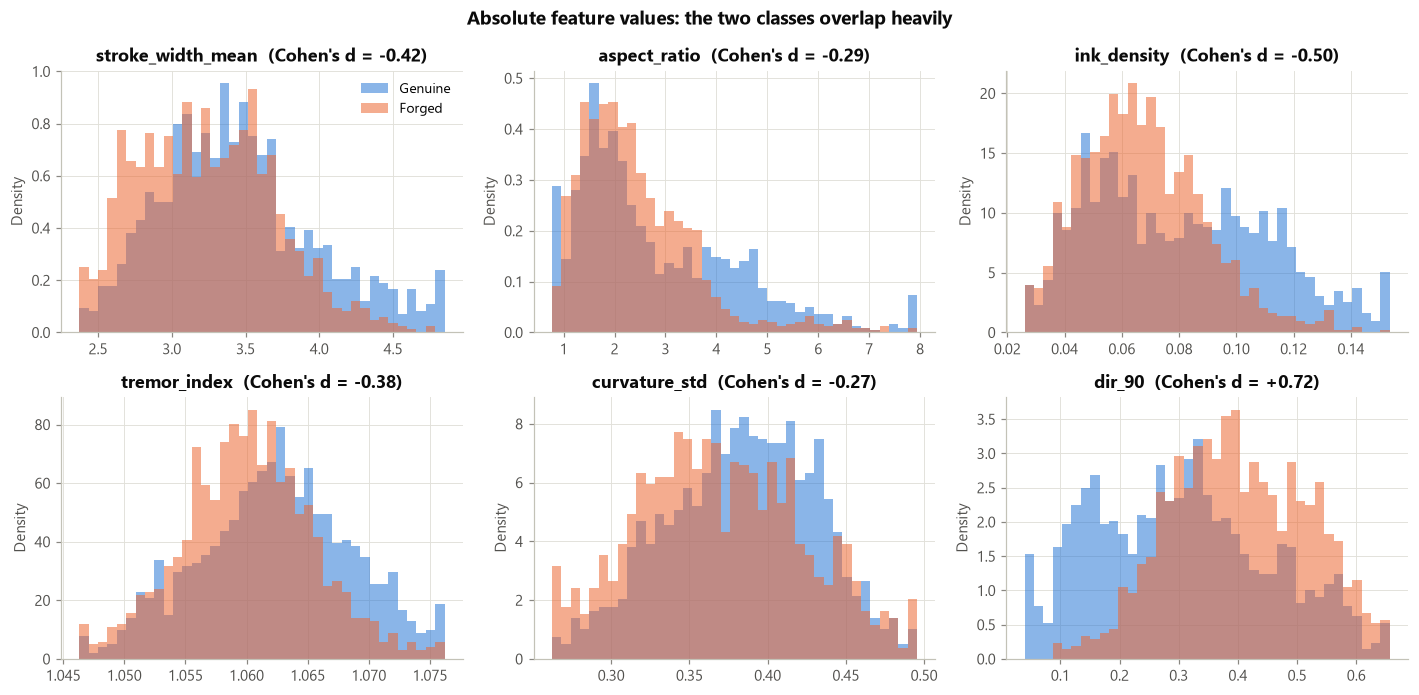

In [11]:
key = ["stroke_width_mean", "aspect_ratio", "ink_density", "tremor_index", "curvature_std", "dir_90"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4))
for ax, feat in zip(axes.ravel(), key):
    lo, hi = records[feat].quantile([0.005, 0.995])
    bins = np.linspace(lo, hi, 40)
    for lab in (0, 1):
        ax.hist(records.loc[records.label == lab, feat].clip(lo, hi), bins=bins, alpha=0.55,
                color=P.CLASS_COLORS[lab], label=config.CLASS_NAMES[lab], density=True)
    d = cohens_d(records[feat], records.label)
    ax.set_title(f"{feat}  (Cohen's d = {d:+.2f})")
    ax.set_ylabel("Density")
axes[0, 0].legend()
fig.suptitle("Absolute feature values: the two classes overlap heavily", fontsize=12.5, fontweight="bold",
             color=P.INK)
fig.tight_layout()
P.save(fig, "fig05_feature_distributions")
plt.show()

### 5.2 Between-writer variation vs genuine/forged variation
Each box below is one writer. Within a writer the forgery (orange) is often clearly different from the
genuine signatures (blue), but **the level itself changes from writer to writer** - a value that is
"normal" for one writer is "suspicious" for another.

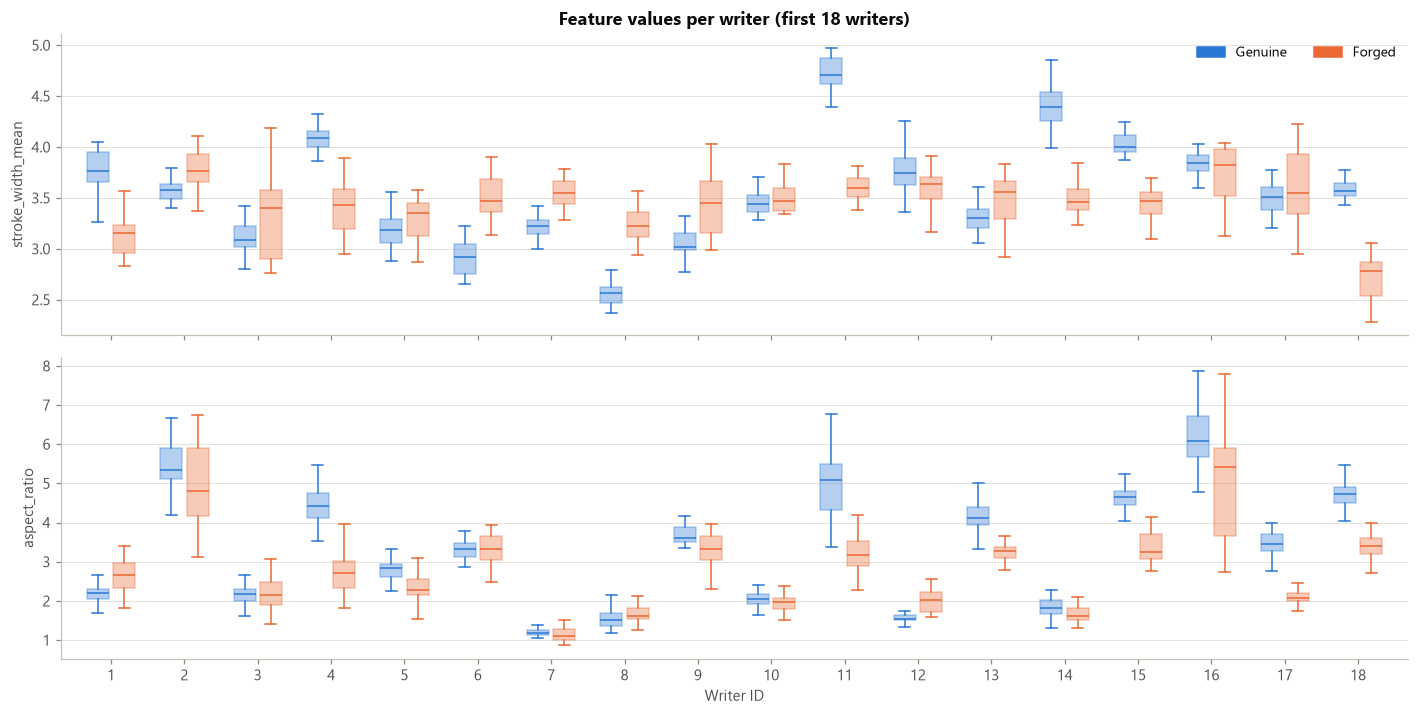

In [12]:
show_w = sorted(records.writer.unique())[:18]
fig, axes = plt.subplots(2, 1, figsize=(13, 6.6), sharex=True)
for ax, feat in zip(axes, ["stroke_width_mean", "aspect_ratio"]):
    for i, wr in enumerate(show_w):
        for lab, off in ((0, -0.18), (1, 0.18)):
            vals = records.loc[(records.writer == wr) & (records.label == lab), feat]
            bp = ax.boxplot(vals, positions=[i + off], widths=0.3, patch_artist=True, showfliers=False)
            for part in ("boxes", "whiskers", "caps", "medians"):
                for item in bp[part]:
                    item.set_color(P.CLASS_COLORS[lab])
            bp["boxes"][0].set_facecolor(P.CLASS_COLORS[lab]); bp["boxes"][0].set_alpha(0.35)
    ax.set_ylabel(feat)
    ax.grid(axis="x", visible=False)
axes[1].set_xticks(range(len(show_w)), [str(w) for w in show_w])
axes[1].set_xlabel("Writer ID")
P.class_legend(axes[0], loc="upper right", ncol=2)
axes[0].set_title("Feature values per writer (first 18 writers)")
fig.tight_layout()
P.save(fig, "fig06_writer_variation")
plt.show()

Median share of variance explained by WRITER identity : 0.625
Median share of variance explained by GENUINE/FORGED  : 0.003
Features where class explains more than writer        : 0 of 49


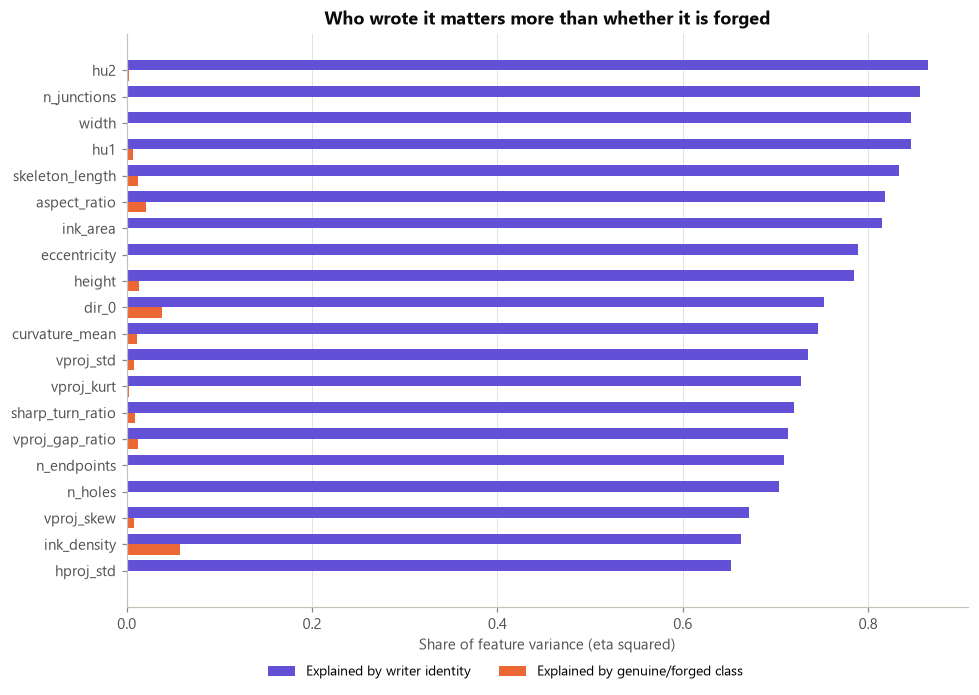

In [13]:
var_dec = pd.DataFrame({
    "eta2_writer": [eta_squared(records[f], records.writer) for f in F],
    "eta2_class": [eta_squared(records[f], records.label) for f in F],
}, index=F)
var_dec["ratio"] = var_dec.eta2_writer / var_dec.eta2_class.clip(lower=1e-6)
print("Median share of variance explained by WRITER identity :", f"{var_dec.eta2_writer.median():.3f}")
print("Median share of variance explained by GENUINE/FORGED  :", f"{var_dec.eta2_class.median():.3f}")
print("Features where class explains more than writer        :", int((var_dec.eta2_class > var_dec.eta2_writer).sum()), "of", len(F))

top = var_dec.sort_values("eta2_writer", ascending=True).tail(20)
fig, ax = plt.subplots(figsize=(9, 6.4))
y = np.arange(len(top))
ax.barh(y + 0.2, top.eta2_writer, height=0.4, color=P.MAIN, label="Explained by writer identity")
ax.barh(y - 0.2, top.eta2_class, height=0.4, color=P.FORGED, label="Explained by genuine/forged class")
ax.set_yticks(y, top.index)
ax.set_xlabel("Share of feature variance (eta squared)")
ax.set_title("Who wrote it matters more than whether it is forged")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.08), ncol=2)
ax.grid(axis="y", visible=False)
fig.tight_layout()
P.save(fig, "fig07_variance_writer_vs_class")
plt.show()

**Key EDA finding.** For almost every feature, *writer identity* explains far more variance than the
genuine/forged label. A classifier that looks at absolute feature values therefore mostly learns who wrote
the signature, not whether it is genuine. This is exactly why banks compare a cheque signature with the
**specimen signatures on file**. Experiment 2 builds features *relative to the writer's own reference
signatures* to remove this writer effect.

### 5.3 Correlation between features

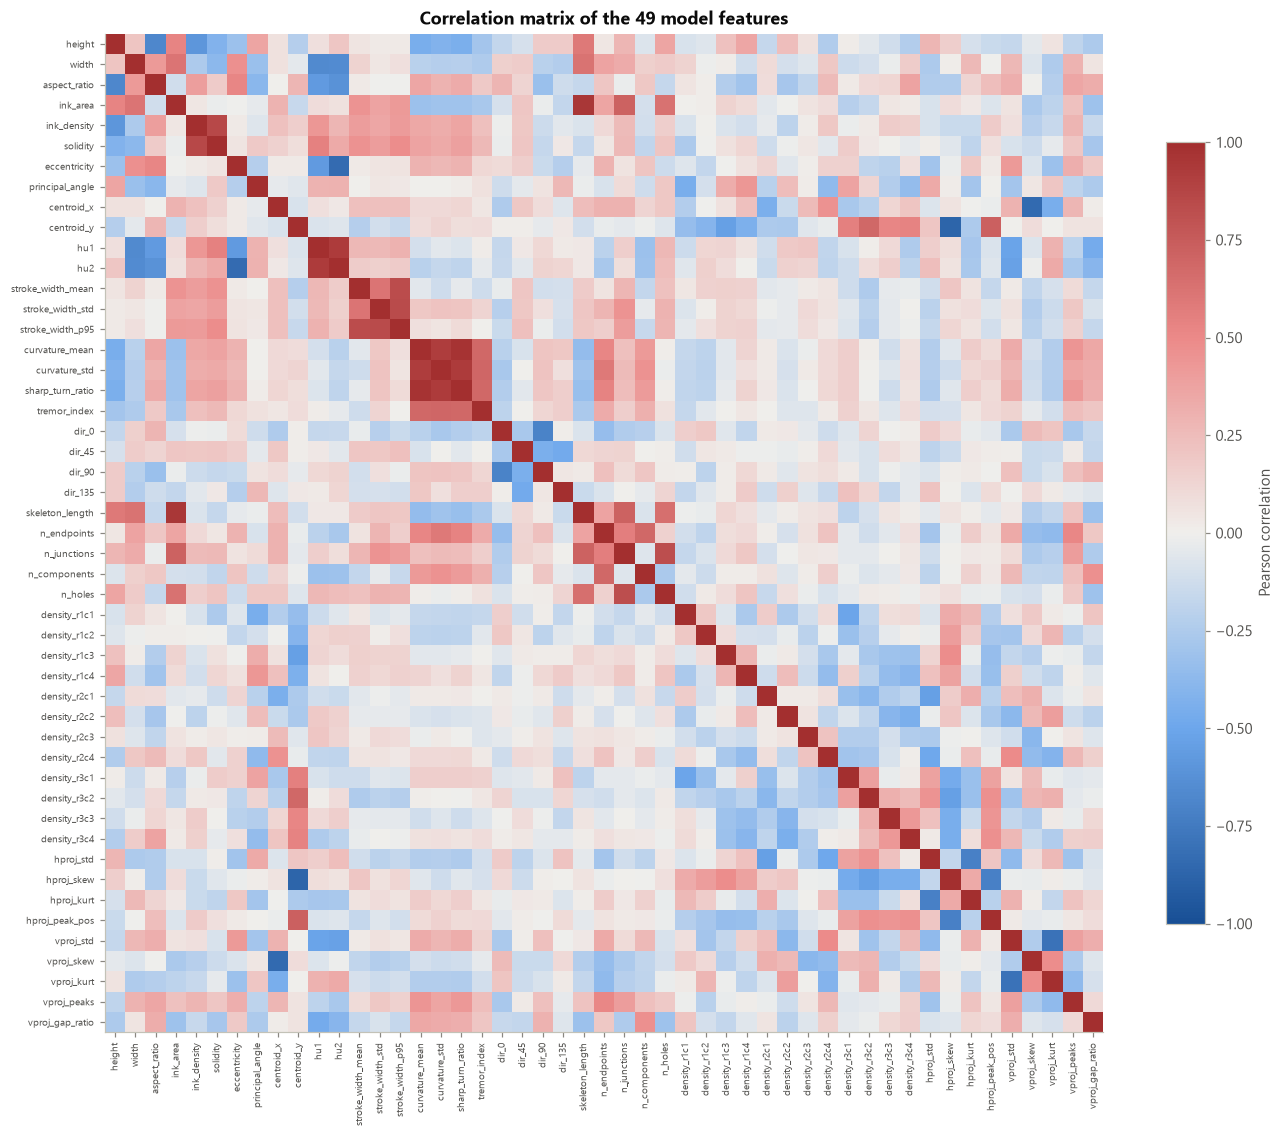

Most strongly correlated feature pairs:


,feature_1,feature_2,r,abs_r
752,curvature_mean,sharp_turn_ratio,0.9705,0.9705
170,ink_area,skeleton_length,0.9498,0.9498
501,hu1,hu2,0.9244,0.9244
801,curvature_std,sharp_turn_ratio,0.9228,0.9228
751,curvature_mean,curvature_std,0.9150,0.9150
482,centroid_y,hproj_skew,-0.8687,0.8687
201,ink_density,solidity,0.8574,0.8574
437,centroid_x,vproj_skew,-0.8427,0.8427
651,stroke_width_std,stroke_width_p95,0.8369,0.8369
305,eccentricity,hu2,-0.8354,0.8354


In [14]:
corr = records[F].corr()
fig, ax = plt.subplots(figsize=(12.5, 10.5))
im = ax.imshow(corr, cmap=P.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(F)), F, rotation=90, fontsize=6.5)
ax.set_yticks(range(len(F)), F, fontsize=6.5)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.75)
cb.set_label("Pearson correlation")
ax.set_title(f"Correlation matrix of the {len(F)} model features")
fig.tight_layout()
P.save(fig, "fig08_correlation_heatmap")
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("r").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["abs_r"] = pairs.r.abs()
print("Most strongly correlated feature pairs:")
display(pairs.sort_values("abs_r", ascending=False).head(10))

Correlated groups are expected (e.g. ink area, skeleton length and width all grow with signature size).
Highly correlated features carry duplicate information, make linear-model coefficients unstable and
inflate distances in KNN, so we drop one of every pair with |r| > 0.95 (fitted on the training set only),
and additionally let **L1 regularization** select features.

## 6. Writer-wise train / test split

A random split would put signatures of the same writer in both training and test sets, so the test score
would measure *memorising writers* and be over-optimistic. We split **by writer**: 44 writers (80 %) for
training and validation, and 11 writers (20 %) that the model **never sees** for the final test.
Inside the training writers, every hyper-parameter search uses **GroupKFold (5 folds, grouped by writer)**.

In [15]:
writers = np.array(sorted(records.writer.unique()))
gss = GroupShuffleSplit(n_splits=1, test_size=config.TEST_WRITER_FRACTION, random_state=config.RANDOM_STATE)
tr_idx, te_idx = next(gss.split(writers, groups=writers))
train_writers, test_writers = sorted(writers[tr_idx].tolist()), sorted(writers[te_idx].tolist())
assert not set(train_writers) & set(test_writers)
print(f"Train writers ({len(train_writers)}):", train_writers)
print(f"Test writers  ({len(test_writers)}):", test_writers)

Train writers (44): [1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 28, 29, 30, 31, 34, 35, 36, 37, 38, 39, 40, 41, 43, 45, 46, 47, 48, 49, 51, 52, 54, 55]
Test writers  (11): [6, 13, 14, 20, 27, 32, 33, 42, 44, 50, 53]


### Reference signatures and the questioned set
For every writer, **5 genuine signatures** (chosen at random with a fixed seed) are kept aside as the
"specimen signatures on file". All remaining signatures - 19 genuine + 24 forged per writer - are the
**questioned signatures** that the models classify. Both experiments use exactly the same questioned
signatures, so their results are directly comparable.

In [16]:
is_ref = select_references(records, config.N_REFERENCES, config.RANDOM_STATE)
ref_train_mask = is_ref & records.writer.isin(train_writers)
scale = pooled_within_writer_std(records.loc[ref_train_mask, F], records.loc[ref_train_mask, "writer"])

refset = build_reference_dataset(records, F, is_ref, scale)            # Experiment 2 features
refset = refset.sort_values("row_id").reset_index(drop=True)
absset = records.loc[refset.row_id].reset_index(drop=True)            # Experiment 1 features (same rows)

y_all = refset["label"].to_numpy()
w_all = refset["writer"].to_numpy()
is_train = np.isin(w_all, train_writers)
is_test = ~is_train
y_tr, y_te = y_all[is_train], y_all[is_test]
g_tr = w_all[is_train]

split_tbl = pd.DataFrame({
    "Writers": [len(train_writers), len(test_writers)],
    "Questioned signatures": [is_train.sum(), is_test.sum()],
    "Genuine": [(y_tr == 0).sum(), (y_te == 0).sum()],
    "Forged": [(y_tr == 1).sum(), (y_te == 1).sum()],
}, index=["Train (CV)", "Test (unseen writers)"])
display(split_tbl)
split_tbl.to_csv(config.TABLE_DIR / "split_summary.csv")

,Writers,Questioned signatures,Genuine,Forged
Train (CV),44,1892,836,1056
Test (unseen writers),11,473,209,264


## 7. Experiment 1 - absolute features (no reference signatures)
The model sees only the 49 model features of the questioned signature itself.
A smaller grid is used here because this is a diagnostic experiment.

In [17]:
kept_A, dropped_A = correlation_filter(absset.loc[is_train, F])
print(f"Experiment 1: kept {len(kept_A)} of {len(F)} features after the correlation filter")
display(dropped_A)
XA_tr, XA_te = absset.loc[is_train, kept_A], absset.loc[is_test, kept_A]

zoo_A = model_zoo(fast=True)
t0 = time.time()
searches_A = tune_all(XA_tr, y_tr, g_tr, zoo_A)
final_A = finalize(searches_A, XA_tr, y_tr)
print(f"Tuning time: {time.time() - t0:.0f}s")
cv_A = cv_table(searches_A, zoo_A)
test_A = test_table(final_A, XA_te, y_te)
res_A = cv_A[["Model", "CV roc_auc", "CV roc_auc std"]].merge(test_A, on="Model")
res_A.to_csv(config.TABLE_DIR / "results_experiment1_absolute.csv", index=False)
display(res_A.round(4))

Experiment 1: kept 47 of 49 features after the correlation filter


,feature,correlated_with,abs_r,reason
0,sharp_turn_ratio,curvature_mean,0.9680,|r| > 0.95
1,skeleton_length,ink_area,0.9510,|r| > 0.95


LogReg (no penalty)    CV AUC = 0.8031  (  2.1s)  best = {}


LogReg + L2 (Ridge)    CV AUC = 0.8037  (  2.4s)  best = {'lr__C': np.float64(10.0)}


LogReg + L1 (Lasso)    CV AUC = 0.8038  (  3.1s)  best = {'lr__C': np.float64(1.0)}


SVM                    CV AUC = 0.8022  (  4.7s)  best = {'svm__C': 1, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}


... (3 outputs left out)

Gradient Boosting      CV AUC = 0.8314  ( 25.4s)  best = {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300, 'subsample': 0.8}


AdaBoost               CV AUC = 0.8196  ( 31.4s)  best = {'estimator__max_depth': 2, 'learning_rate': 0.1, 'n_estimators': 300}


Tuning time: 98s


,Model,CV roc_auc,CV roc_auc std,Accuracy,Precision,Recall,F1,ROC_AUC,FAR,FRR,EER,Predict time (ms)
0,LogReg (no penalty),0.8031,0.0280,0.7484,0.7302,0.8712,0.7945,0.8136,0.1288,0.4067,0.3041,21.5085
1,LogReg + L2 (Ridge),0.8037,0.0275,0.7484,0.7302,0.8712,0.7945,0.8146,0.1288,0.4067,0.3041,21.0073
2,LogReg + L1 (Lasso),0.8038,0.0281,0.7421,0.7261,0.8636,0.7889,0.8195,0.1364,0.4115,0.2894,20.0031
3,SVM,0.8022,0.0246,0.7780,0.7461,0.9129,0.8211,0.8588,0.0871,0.3923,0.2304,113.0950
4,KNN,0.7478,0.0300,0.6850,0.6542,0.9242,0.7661,0.7765,0.0758,0.6172,0.2734,155.3273
5,Decision Tree,0.7066,0.0451,0.6977,0.6921,0.8258,0.7530,0.6597,0.1742,0.4641,0.3336,20.0083
6,Random Forest,0.8129,0.0537,0.7315,0.6866,0.9545,0.7987,0.8590,0.0455,0.5502,0.2051,67.0907
7,Gradient Boosting,0.8314,0.0476,0.7421,0.7261,0.8636,0.7889,0.8306,0.1364,0.4115,0.2432,20.9980
8,AdaBoost,0.8196,0.0559,0.7463,0.7169,0.9015,0.7987,0.8238,0.0985,0.4498,0.2518,130.6162


Even the best model on absolute features stays well below what a deployable verifier needs. This
confirms the EDA finding: without knowing what the writer's genuine signature looks like, the features
mostly encode *who* wrote the signature.

## 8. Experiment 2 - writer-normalised (reference-based) features - final system

For a questioned signature *q* of writer *w*, every feature is turned into a **deviation from the writer's
own reference signatures**:

$$\text{dev}_j = \log\!\Big(1 + \frac{|x_{qj} - \bar{x}_{\text{ref},j}|}{\sigma_j}\Big),\qquad
\sigma_j = \sqrt{\tfrac{1}{2}\big(s_{\text{ref},j}^2 + s_{\text{pooled},j}^2\big)}$$

* $\bar{x}_{\text{ref},j}$, $s_{\text{ref},j}$: mean and std of feature *j* over the writer's 5 references;
* $s_{\text{pooled},j}$: average within-writer std of feature *j*, computed **on training writers only**
  (it stabilises the noisy 5-sample std);
* `log1p` compresses very large deviations.

Three distance statistics are added: mean and minimum distance from *q* to the references, and that mean
distance divided by the typical distance among the references themselves.
One model then works for **any writer** (writer-independent), including writers never seen in training.

In [18]:
DEV = [c for c in refset.columns if c.startswith("dev_")] + DIST_FEATURES
print("Experiment 2 features:", len(DEV))
display(refset[["file", "writer", "label"] + DEV[:4] + DIST_FEATURES].head())

Experiment 2 features: 52


,file,writer,label,dev_height,dev_width,dev_aspect_ratio,dev_ink_area,ref_dist_mean,ref_dist_min,ref_dist_ratio
0,original_1_1.png,1,0,0.8307,0.3837,0.6921,0.8622,1.4011,0.9739,0.9157
1,original_1_3.png,1,0,0.9899,0.3509,1.0678,0.1788,1.2586,0.8544,0.8225
2,original_1_4.png,1,0,0.7349,0.4036,0.5561,0.8921,1.1146,0.7883,0.7285
3,original_1_5.png,1,0,0.7679,0.1584,0.6699,0.4103,1.2662,0.8151,0.8275
4,original_1_6.png,1,0,1.0487,1.2640,0.5809,1.0016,1.4591,0.7408,0.9535


Median |Cohen's d|  absolute features : 0.12
Median |Cohen's d|  reference features: 0.67
Distance features |d|: {'ref_dist_mean': 1.75, 'ref_dist_min': 2.07, 'ref_dist_ratio': 1.79}


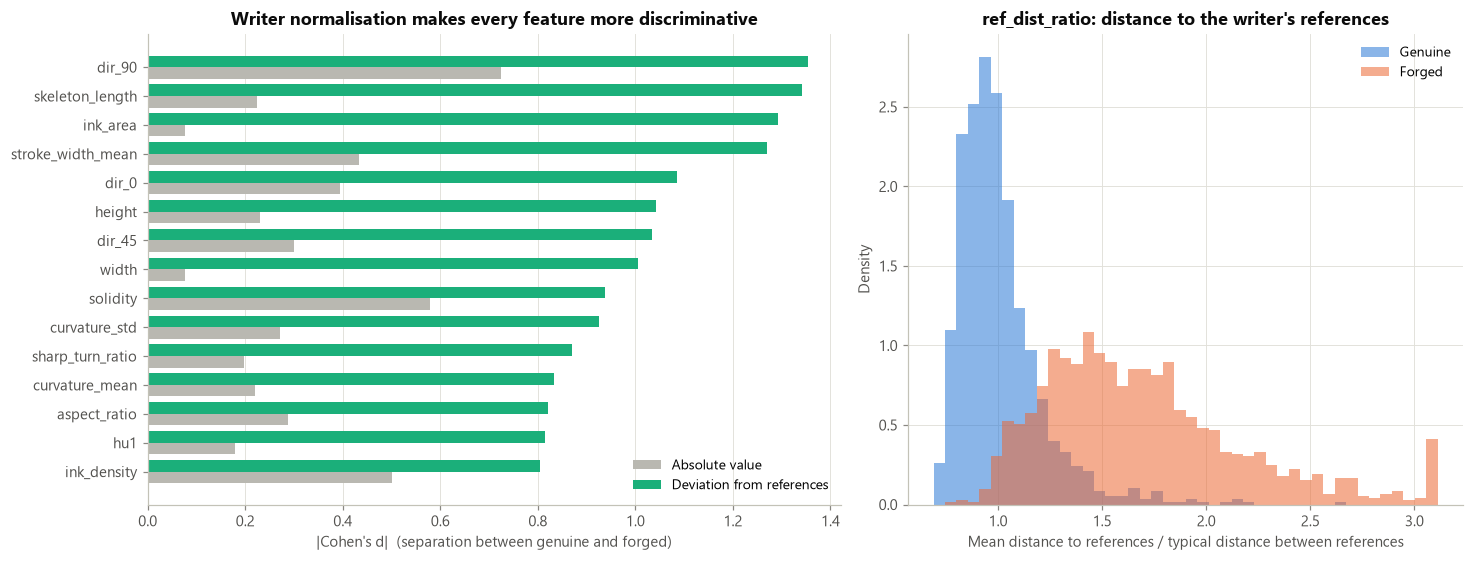

In [19]:
eff = pd.DataFrame({
    "feature": F,
    "abs_d_absolute": [abs(cohens_d(absset[f], absset.label)) for f in F],
    "abs_d_reference": [abs(cohens_d(refset[f"dev_{f}"], refset.label)) for f in F],
})
print("Median |Cohen's d|  absolute features :", f"{eff.abs_d_absolute.median():.2f}")
print("Median |Cohen's d|  reference features:", f"{eff.abs_d_reference.median():.2f}")
print("Distance features |d|:", {f: round(abs(cohens_d(refset[f], refset.label)), 2) for f in DIST_FEATURES})

top_eff = eff.sort_values("abs_d_reference").tail(15)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
yy = np.arange(len(top_eff))
axes[0].barh(yy - 0.2, top_eff.abs_d_absolute, height=0.4, color=P.NEUTRAL, label="Absolute value")
axes[0].barh(yy + 0.2, top_eff.abs_d_reference, height=0.4, color=P.TRIO[0], label="Deviation from references")
axes[0].set_yticks(yy, top_eff.feature)
axes[0].set_xlabel("|Cohen's d|  (separation between genuine and forged)")
axes[0].set_title("Writer normalisation makes every feature more discriminative")
axes[0].legend(loc="lower right")
axes[0].grid(axis="y", visible=False)
feat_show = "ref_dist_ratio"
lo, hi = refset[feat_show].quantile([0.0, 0.99])
bins = np.linspace(lo, hi, 45)
for lab in (0, 1):
    axes[1].hist(refset.loc[refset.label == lab, feat_show].clip(upper=hi), bins=bins, alpha=0.55,
                 density=True, color=P.CLASS_COLORS[lab], label=config.CLASS_NAMES[lab])
axes[1].set_title(f"{feat_show}: distance to the writer's references")
axes[1].set_xlabel("Mean distance to references / typical distance between references")
axes[1].set_ylabel("Density")
axes[1].legend()
fig.tight_layout()
P.save(fig, "fig09_reference_features")
plt.show()

### 8.1 Feature selection for Experiment 2
1. **Correlation filter** (|r| > 0.95, training writers only) removes redundant features.
2. **Filter ranking** with the ANOVA F-score and mutual information (shown for interpretation).
3. **Embedded selection** with L1 (Lasso) regularization in Section 9.

Experiment 2: kept 51 of 52 features after the correlation filter


,feature,correlated_with,abs_r,reason
0,ref_dist_min,ref_dist_mean,0.9650,|r| > 0.95


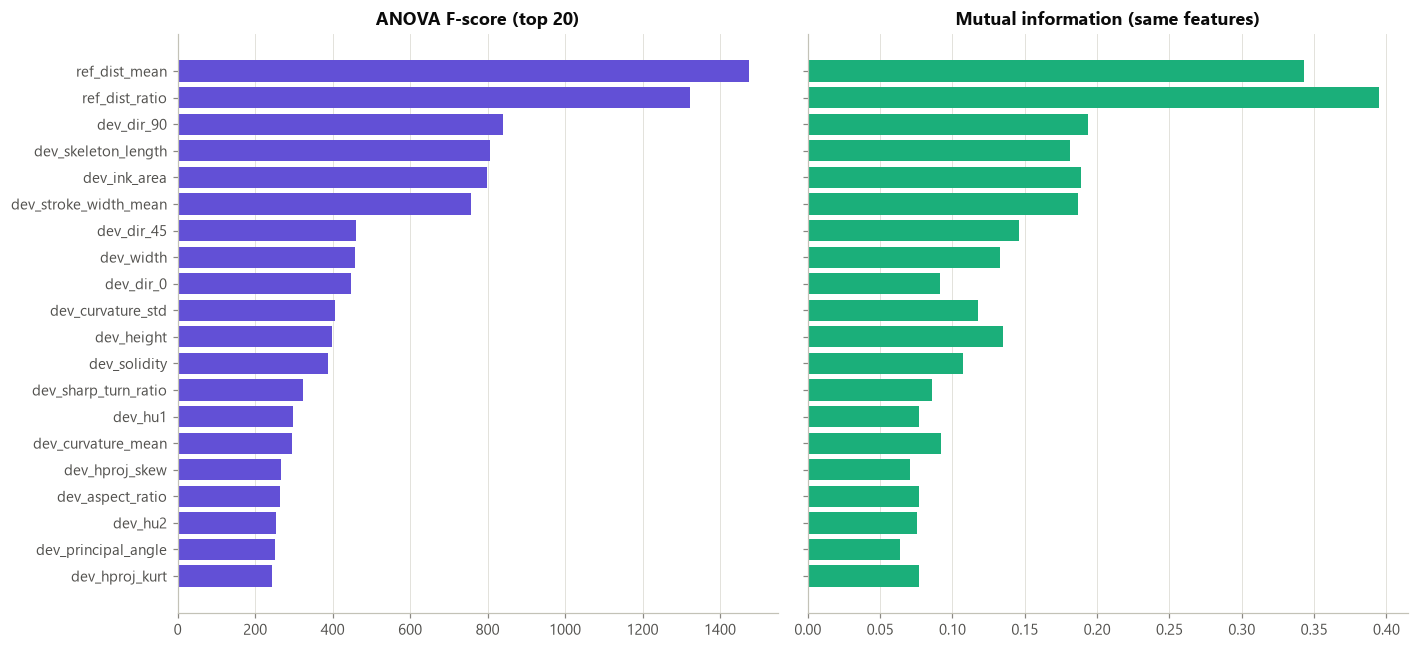

In [20]:
kept_B, dropped_B = correlation_filter(refset.loc[is_train, DEV])
print(f"Experiment 2: kept {len(kept_B)} of {len(DEV)} features after the correlation filter")
display(dropped_B)
pd.concat([dropped_A.assign(experiment="1 absolute"), dropped_B.assign(experiment="2 reference")]).to_csv(
    config.TABLE_DIR / "dropped_features.csv", index=False)

X_tr = refset.loc[is_train, kept_B]
X_te = refset.loc[is_test, kept_B]

f_scores, _ = f_classif(X_tr, y_tr)
mi = mutual_info_classif(X_tr, y_tr, random_state=config.RANDOM_STATE)
rank = pd.DataFrame({"ANOVA F": f_scores, "Mutual information": mi}, index=kept_B).sort_values("ANOVA F")
rank.to_csv(config.TABLE_DIR / "feature_ranking.csv")
top_rank = rank.tail(20)
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
axes[0].barh(top_rank.index, top_rank["ANOVA F"], color=P.MAIN)
axes[0].set_title("ANOVA F-score (top 20)")
axes[1].barh(top_rank.index, top_rank["Mutual information"], color=P.TRIO[0])
axes[1].set_title("Mutual information (same features)")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.tight_layout()
P.save(fig, "fig10_feature_ranking")
plt.show()

## 9. Baseline and regularization (Logistic Regression)

**Why Logistic Regression as the baseline?** It is the simplest probabilistic linear classifier: it models
$P(\text{forged}\mid x) = \sigma(w^\top x + b)$, trains fast, and its coefficients are directly interpretable.
Every other model has to beat it to justify its extra complexity.

**Regularization** adds a penalty on the weights to the log-loss, controlled by $C = 1/\lambda$
(smaller $C$ = stronger penalty):
* **L2 / Ridge**: $\lambda\sum w_j^2$ shrinks all weights smoothly; handles correlated features by spreading
  weight across them; reduces variance (over-fitting).
* **L1 / Lasso**: $\lambda\sum |w_j|$ drives weak weights to **exactly zero**, i.e. automatic feature selection.

LogReg (no penalty)    CV AUC = 0.9698  (  0.2s)  best = {}


LogReg + L2 (Ridge)    CV AUC = 0.9710  (  1.0s)  best = {'lr__C': np.float64(0.1)}


LogReg + L1 (Lasso)    CV AUC = 0.9722  (  1.0s)  best = {'lr__C': np.float64(0.31622776601683794)}


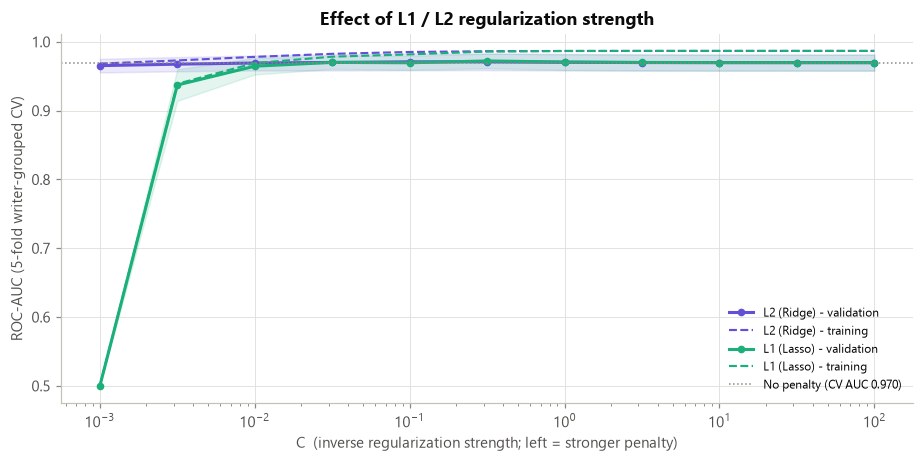

In [21]:
zoo_B = model_zoo(fast=FAST_MODE)
lr_names = ["LogReg (no penalty)", "LogReg + L2 (Ridge)", "LogReg + L1 (Lasso)"]
searches_lr = tune_all(X_tr, y_tr, g_tr, {k: zoo_B[k] for k in lr_names})

curve_l2 = param_curve(searches_lr["LogReg + L2 (Ridge)"], "lr__C").astype(float)
curve_l1 = param_curve(searches_lr["LogReg + L1 (Lasso)"], "lr__C").astype(float)
pd.DataFrame({"C": curve_l2.value, "l2_train": curve_l2.train_auc, "l2_val": curve_l2.val_auc,
              "l1_train": curve_l1.train_auc, "l1_val": curve_l1.val_auc}).to_csv(
    config.TABLE_DIR / "regularization_curve.csv", index=False)

fig, ax = plt.subplots(figsize=(8.5, 4.3))
for name, color in (("LogReg + L2 (Ridge)", P.TRIO[1]), ("LogReg + L1 (Lasso)", P.TRIO[0])):
    cur = param_curve(searches_lr[name], "lr__C").astype(float)
    ax.plot(cur.value, cur.val_auc, "-o", color=color, ms=4, label=f"{name.split('+ ')[1]} - validation")
    ax.plot(cur.value, cur.train_auc, "--", color=color, lw=1.4, label=f"{name.split('+ ')[1]} - training")
    ax.fill_between(cur.value, cur.val_auc - cur.val_std, cur.val_auc + cur.val_std, color=color, alpha=0.12)
base_auc = searches_lr["LogReg (no penalty)"].best_score_
ax.axhline(base_auc, color=P.MUTED, lw=1, ls=":", label=f"No penalty (CV AUC {base_auc:.3f})")
ax.set_xscale("log")
ax.set_xlabel("C  (inverse regularization strength; left = stronger penalty)")
ax.set_ylabel("ROC-AUC (5-fold writer-grouped CV)")
ax.set_title("Effect of L1 / L2 regularization strength")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
P.save(fig, "fig11_regularization_curves")
plt.show()

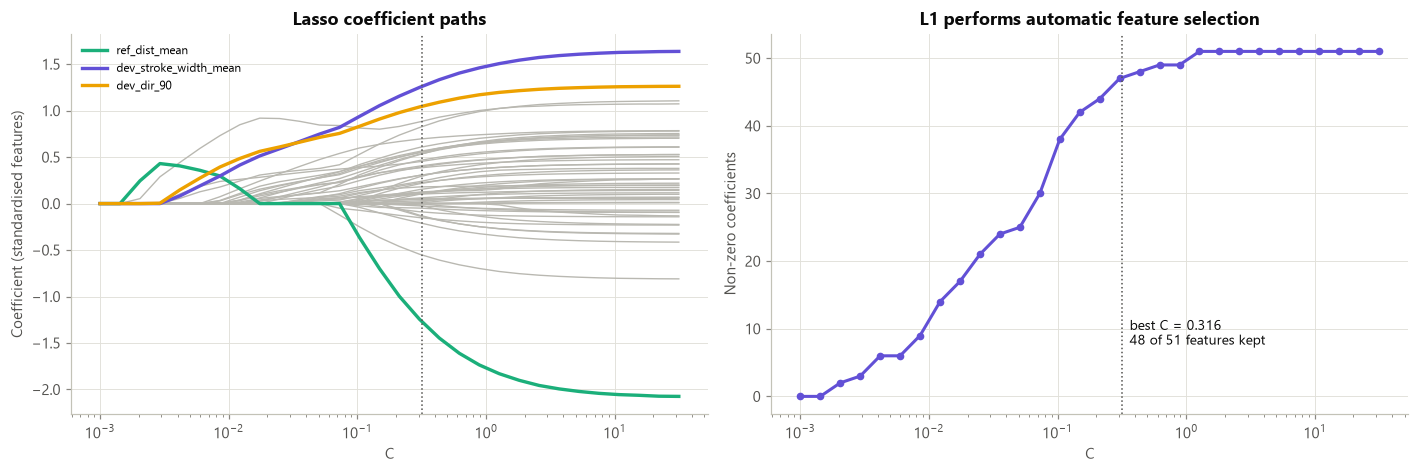

In [22]:
Cs = np.logspace(-3, 1.5, 30)
sc = StandardScaler().fit(X_tr)
Xs = sc.transform(X_tr)
coefs = np.array([LogisticRegression(l1_ratio=1.0, solver="liblinear", C=c, max_iter=5000)
                  .fit(Xs, y_tr).coef_.ravel() for c in Cs])
best_C_l1 = searches_lr["LogReg + L1 (Lasso)"].best_params_["lr__C"]
final_l1 = searches_lr["LogReg + L1 (Lasso)"].best_estimator_
w_best = pd.Series(final_l1.named_steps["lr"].coef_.ravel(), index=kept_B)
top3 = w_best.abs().sort_values(ascending=False).index[:3]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for j, feat in enumerate(kept_B):
    if feat in top3:
        continue
    axes[0].plot(Cs, coefs[:, j], color=P.NEUTRAL, lw=0.9)
for feat, color in zip(top3, P.TRIO):
    j = kept_B.index(feat)
    axes[0].plot(Cs, coefs[:, j], color=color, lw=2.2, label=feat)
axes[0].axvline(best_C_l1, color=P.INK_2, ls=":", lw=1)
axes[0].set_xscale("log")
axes[0].set(xlabel="C", ylabel="Coefficient (standardised features)", title="Lasso coefficient paths")
axes[0].legend(fontsize=8)
nz = (np.abs(coefs) > 1e-8).sum(axis=1)
axes[1].plot(Cs, nz, "-o", color=P.MAIN, ms=4)
axes[1].axvline(best_C_l1, color=P.INK_2, ls=":", lw=1)
axes[1].text(best_C_l1 * 1.15, nz.max() * 0.15, f"best C = {best_C_l1:.3g}\n"
             f"{int((w_best.abs() > 1e-8).sum())} of {len(kept_B)} features kept", fontsize=9, color=P.INK)
axes[1].set_xscale("log")
axes[1].set(xlabel="C", ylabel="Non-zero coefficients", title="L1 performs automatic feature selection")
fig.tight_layout()
P.save(fig, "fig12_lasso_path")
plt.show()

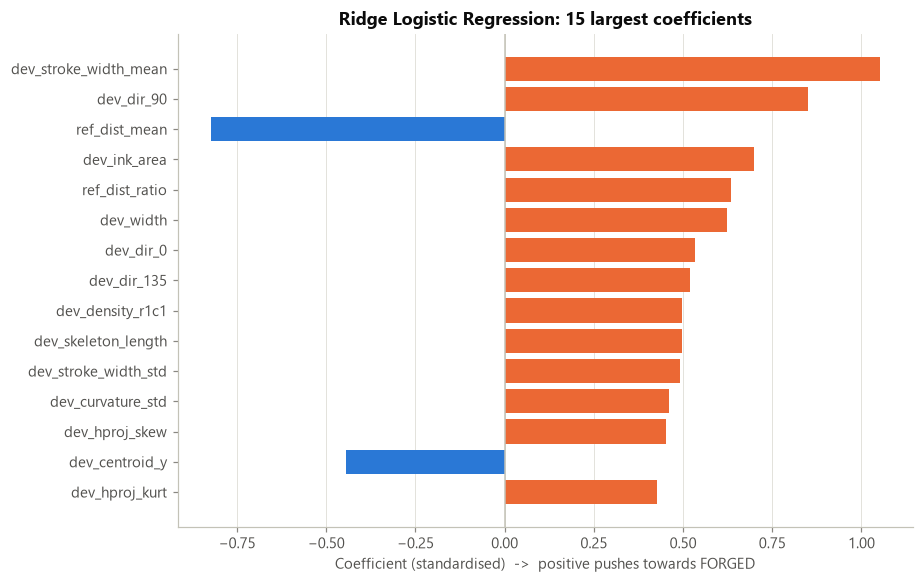

,Model,Best C,CV ROC-AUC,Train ROC-AUC,Non-zero coefficients,Train - CV gap
0,LogReg (no penalty),inf,0.9698,0.9868,51,0.0170
1,LogReg + L2 (Ridge),0.1000,0.9710,0.9852,51,0.0143
2,LogReg + L1 (Lasso),0.3162,0.9722,0.9859,48,0.0137


In [23]:
final_l2 = searches_lr["LogReg + L2 (Ridge)"].best_estimator_
w_l2 = pd.Series(final_l2.named_steps["lr"].coef_.ravel(), index=kept_B)
top_w = w_l2.reindex(w_l2.abs().sort_values().index).tail(15)
fig, ax = plt.subplots(figsize=(8.5, 5.4))
ax.barh(top_w.index, top_w.values, color=[P.FORGED if v > 0 else P.GENUINE for v in top_w.values])
ax.axvline(0, color=P.AXIS, lw=1)
ax.set_xlabel("Coefficient (standardised)  ->  positive pushes towards FORGED")
ax.set_title("Ridge Logistic Regression: 15 largest coefficients")
ax.grid(axis="y", visible=False)
fig.tight_layout()
P.save(fig, "fig13_lr_coefficients")
plt.show()

lr_tbl = pd.DataFrame({
    "Model": lr_names,
    "Best C": [np.inf, searches_lr[lr_names[1]].best_params_["lr__C"], best_C_l1],
    "CV ROC-AUC": [searches_lr[n].best_score_ for n in lr_names],
    "Train ROC-AUC": [searches_lr[n].cv_results_["mean_train_roc_auc"][searches_lr[n].best_index_] for n in lr_names],
    "Non-zero coefficients": [int((np.abs(searches_lr[n].best_estimator_.named_steps["lr"].coef_) > 1e-8).sum())
                              for n in lr_names],
})
lr_tbl["Train - CV gap"] = lr_tbl["Train ROC-AUC"] - lr_tbl["CV ROC-AUC"]
display(lr_tbl)
lr_tbl.to_csv(config.TABLE_DIR / "regularization_summary.csv", index=False)

## 10. Hyper-parameter tuning of all models and ensembles

| Model | Why it is included | Tuned hyper-parameters (and their regularizing role) |
|---|---|---|
| Logistic Regression | interpretable linear baseline | penalty type (L1 / L2), C |
| SVM | maximum-margin classifier; RBF kernel captures non-linear boundaries | kernel, C (margin softness), gamma (kernel width) |
| KNN | instance-based: "is this signature close to known forgeries?" | K (small K = over-fit, large K = under-fit), weights, distance metric |
| Decision Tree | human-readable rules | max depth, min samples per leaf, criterion, cost-complexity pruning alpha |
| Random Forest (**bagging**) | averages many de-correlated deep trees -> lower variance | number of trees, depth, features per split, leaf size |
| Gradient Boosting / AdaBoost (**boosting**) | adds shallow trees sequentially, each fixing the previous errors -> lower bias | number of trees, learning rate, tree depth, subsample |
| Soft Voting | averages probabilities of different model families | members = best LR, SVM, RF, GB |

All searches use `GridSearchCV` with **GroupKFold(5)** over the 44 training writers and **ROC-AUC** as the
selection metric (threshold-independent, and robust to the mild 45 / 55 class imbalance of the questioned set).

In [24]:
t0 = time.time()
other = {k: v for k, v in zoo_B.items() if k not in lr_names}
searches_B = {**searches_lr, **tune_all(X_tr, y_tr, g_tr, other)}
final_B = finalize(searches_B, X_tr, y_tr)
final_B = add_voting(final_B, X_tr, y_tr)
print(f"Total tuning time: {time.time() - t0:.0f}s")

cv_B = cv_table(searches_B, zoo_B)
vote_cv = cross_validate(clone(final_B["Soft Voting"]), X_tr, y_tr, groups=g_tr, cv=GroupKFold(config.CV_FOLDS),
                         scoring=SCORING, return_train_score=True, n_jobs=-1)
vote_row = {"Model": "Soft Voting", "Family": "Ensemble (voting)", "Best params": "LR-L2 + SVM + RF + GB",
            "Train AUC": vote_cv["train_roc_auc"].mean()}
for m in SCORING:
    vote_row[f"CV {m}"] = vote_cv[f"test_{m}"].mean()
    vote_row[f"CV {m} std"] = vote_cv[f"test_{m}"].std()
cv_B = pd.concat([cv_B, pd.DataFrame([vote_row])], ignore_index=True)
cv_B.to_csv(config.TABLE_DIR / "cv_results_experiment2.csv", index=False)
display(cv_B[["Model", "Family", "Best params", "CV roc_auc", "CV roc_auc std", "CV accuracy",
              "CV f1", "CV recall", "Train AUC"]].round(4))

SVM                    CV AUC = 0.9719  ( 10.7s)  best = {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}


KNN                    CV AUC = 0.9659  ( 10.4s)  best = {'knn__metric': 'manhattan', 'knn__n_neighbors': 71, 'knn__weights': 'uniform'}


Decision Tree          CV AUC = 0.9576  ( 35.5s)  best = {'ccp_alpha': 0.0, 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 40}


Random Forest          CV AUC = 0.9734  (137.3s)  best = {'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 300}


Gradient Boosting      CV AUC = 0.9745  (209.2s)  best = {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 1.0}


AdaBoost               CV AUC = 0.9777  (347.0s)  best = {'estimator__max_depth': 3, 'learning_rate': 0.05, 'n_estimators': 800}


Total tuning time: 759s


,Model,Family,Best params,CV roc_auc,CV roc_auc std,CV accuracy,CV f1,CV recall,Train AUC
0,LogReg (no penalty),Baseline,-,0.9698,0.0117,0.9028,0.9101,0.8932,0.9868
1,LogReg + L2 (Ridge),Baseline,C=0.1,0.9710,0.0123,0.9068,0.9141,0.8985,0.9852
2,LogReg + L1 (Lasso),Baseline,C=0.31622776601683794,0.9722,0.0106,0.9107,0.9175,0.9016,0.9859
3,SVM,Single model,"C=1, gamma=scale, kernel=rbf",0.9719,0.0113,0.9175,0.9247,0.9188,0.9976
4,KNN,Single model,"metric=manhattan, n_neighbors=71, weights=uniform",0.9659,0.0113,0.8215,0.8111,0.7014,0.9809
5,Decision Tree,Single model,"ccp_alpha=0.0, criterion=entropy, max_depth=5,...",0.9576,0.0126,0.8911,0.9023,0.9069,0.9764
6,Random Forest,Ensemble (bagging),"max_depth=16, max_features=sqrt, min_samples_l...",0.9734,0.0086,0.9169,0.9260,0.9337,0.9997
7,Gradient Boosting,Ensemble (boosting),"learning_rate=0.1, max_depth=3, n_estimators=2...",0.9745,0.0098,0.9149,0.9235,0.9242,1.0000
8,AdaBoost,Ensemble (boosting),"max_depth=3, learning_rate=0.05, n_estimators=800",0.9777,0.0086,0.9150,0.9231,0.9225,1.0000
9,Soft Voting,Ensemble (voting),LR-L2 + SVM + RF + GB,0.9764,0.0088,0.9225,0.9300,0.9294,0.9995


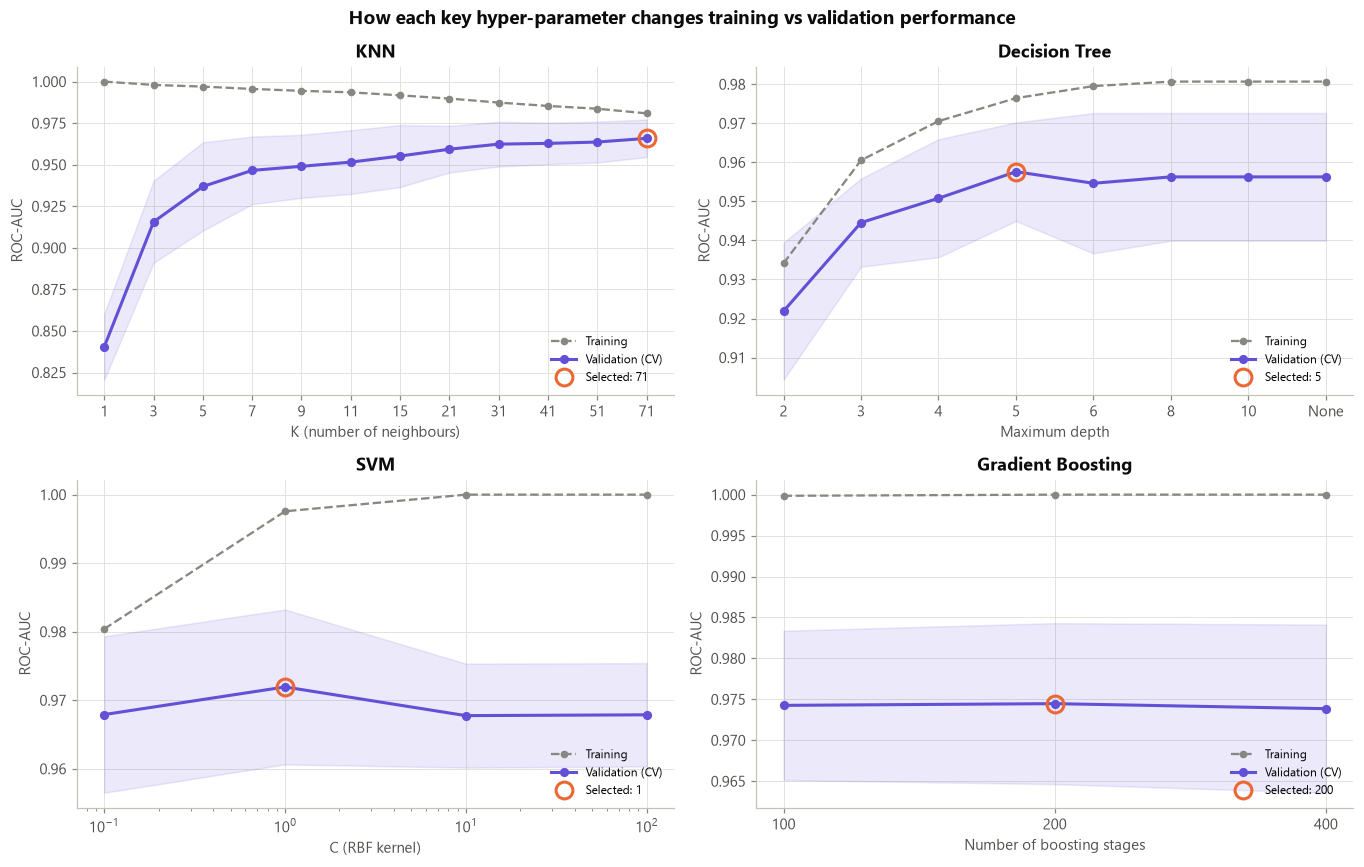

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8))
specs = [
    ("KNN", "knn__n_neighbors", "K (number of neighbours)", False),
    ("Decision Tree", "max_depth", "Maximum depth", False),
    ("SVM", "svm__C", "C (RBF kernel)" if searches_B["SVM"].best_params_["svm__kernel"] == "rbf" else "C (linear kernel)", True),
    ("Gradient Boosting", "n_estimators", "Number of boosting stages", False),
]
for ax, (name, param, label, logx) in zip(axes.ravel(), specs):
    cur = param_curve(searches_B[name], param)
    xs = np.arange(len(cur)) if not logx else cur.value.astype(float)
    ax.plot(xs, cur.train_auc, "--o", color=P.MUTED, ms=4, lw=1.5, label="Training")
    ax.plot(xs, cur.val_auc, "-o", color=P.MAIN, ms=5, label="Validation (CV)")
    ax.fill_between(xs, cur.val_auc - cur.val_std, cur.val_auc + cur.val_std, color=P.MAIN, alpha=0.12)
    best_v = searches_B[name].best_params_[param]
    bi = [k for k, v in enumerate(cur.value) if same_value(v, best_v)][0]
    ax.plot(xs[bi], cur.val_auc[bi], "o", ms=11, mfc="none", mec=P.FORGED, mew=2, label=f"Selected: {best_v}")
    if not logx:
        ax.set_xticks(xs, [str(v) for v in cur.value])
    else:
        ax.set_xscale("log")
    ax.set(xlabel=label, ylabel="ROC-AUC", title=name)
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("How each key hyper-parameter changes training vs validation performance", fontsize=12.5,
             fontweight="bold", color=P.INK)
fig.tight_layout()
P.save(fig, "fig14_hyperparameter_effects")
plt.show()

**Reading the curves.** The gap between the training and validation curves is the over-fitting.
* **KNN:** with distance weighting every training signature is its own nearest neighbour, so the training AUC
  is always 1 (pure memorisation); the validation curve shows the real effect of K - small K follows noise,
  larger K averages over more neighbours and smooths the decision boundary.
* **Decision Tree:** deeper trees keep improving on training data while validation stops improving - pruning
  (limited depth / leaf size / cost-complexity alpha) is the regularizer.
* **SVM:** C trades margin width against training errors; too large C over-fits.
* **Gradient Boosting:** more stages lower the bias; the small learning rate keeps the variance in check.

## 11. Performance analysis on the 11 unseen test writers

In [26]:
order = cv_B.sort_values("CV roc_auc", ascending=False)["Model"].tolist()
best_name = order[0]
print("Model selected by cross-validation (highest CV ROC-AUC):", best_name)

test_B = test_table(final_B, X_te, y_te).set_index("Model").loc[order].reset_index()
test_B.to_csv(config.TABLE_DIR / "test_results_experiment2.csv", index=False)
display(test_B.round(4))

Model selected by cross-validation (highest CV ROC-AUC): AdaBoost


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,FAR,FRR,EER,Predict time (ms)
0,AdaBoost,0.9027,0.9258,0.8977,0.9115,0.9700,0.1023,0.0909,0.0990,497.9644
1,Soft Voting,0.9323,0.9427,0.9356,0.9392,0.9823,0.0644,0.0718,0.0676,133.8546
2,Gradient Boosting,0.9239,0.9286,0.9356,0.9321,0.9733,0.0644,0.0909,0.0748,39.1634
3,Random Forest,0.9218,0.9127,0.9508,0.9314,0.9829,0.0492,0.1148,0.0614,120.0802
4,LogReg + L1 (Lasso),0.9006,0.9157,0.9053,0.9105,0.9576,0.0947,0.1053,0.1076,33.6452
5,SVM,0.9260,0.9387,0.9280,0.9333,0.9809,0.0720,0.0766,0.0743,108.0875
6,LogReg + L2 (Ridge),0.9112,0.9205,0.9205,0.9205,0.9646,0.0795,0.1005,0.0933,37.7991
7,LogReg (no penalty),0.8901,0.9077,0.8939,0.9008,0.9493,0.1061,0.1148,0.1099,42.1028
8,KNN,0.8541,0.9803,0.7538,0.8522,0.9745,0.2462,0.0191,0.0719,73.1430
9,Decision Tree,0.9112,0.8993,0.9470,0.9225,0.9449,0.0530,0.1340,0.0963,25.5556


**Interpretation of the test results**

* The model selected by cross-validation, **AdaBoost**, reaches 90.3% accuracy, ROC-AUC 0.970 and
  EER 9.9% on the 11 unseen writers.
* On the test writers **Random Forest** has the best ROC-AUC (0.983) and Soft Voting the best accuracy
  (93.2%). The top four CV scores differ by less than one CV standard deviation
  (about 0.011), so the CV ranking among them is partly noise: the CV winner of a large
  search tends to be slightly over-optimistic (*winner's curse*). AdaBoost picked its most complex configuration
  (max_depth=3, learning_rate=0.05, n_estimators=800) with training AUC 1.000, i.e. the highest variance.
  We keep the CV-based choice - switching models after looking at the test set would be test-set snooping.
* Bagging works as expected: the single Decision Tree has the lowest test ROC-AUC (0.945),
  Random Forest raises it to 0.983.
* KNN ranks well (ROC-AUC 0.974) but at threshold 0.5 accepts 24.6% of the
  forgeries: its probability (share of forged neighbours) is poorly calibrated, so the threshold matters.

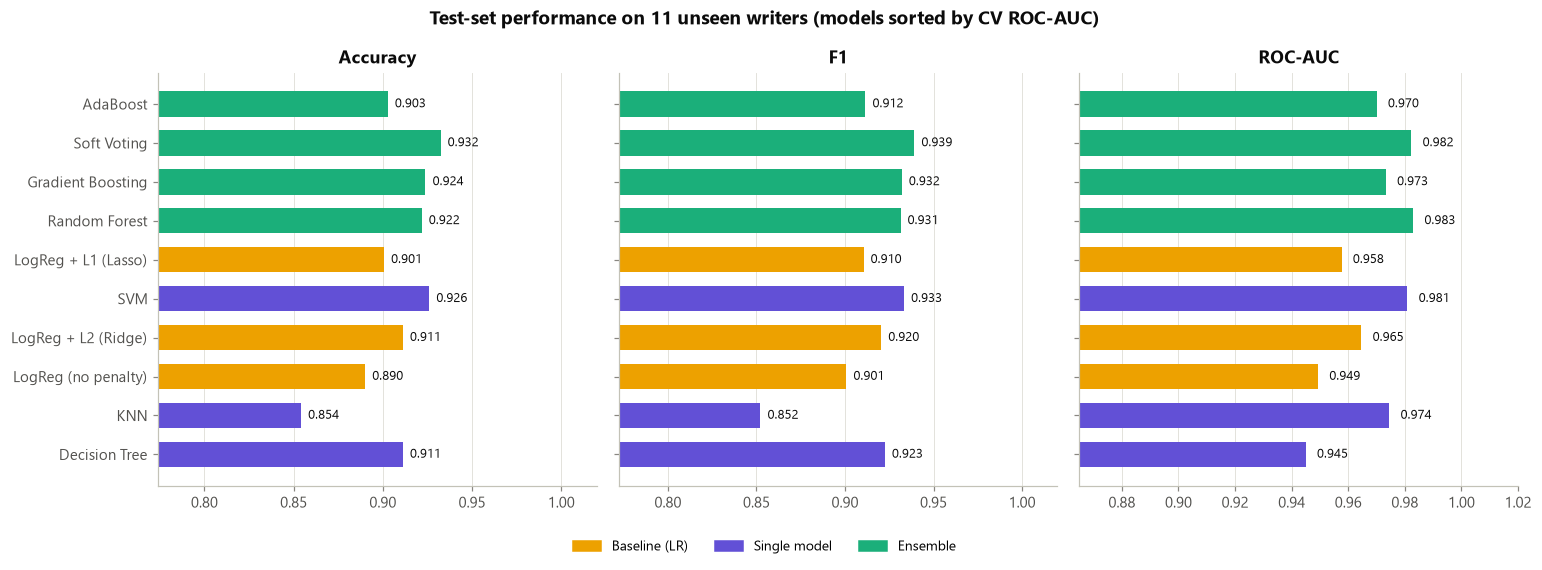

In [27]:
fam = cv_B.set_index("Model")["Family"]
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
ylab = order[::-1]
for ax, metric in zip(axes, ["Accuracy", "F1", "ROC_AUC"]):
    vals = test_B.set_index("Model").loc[ylab, metric]
    ax.barh(ylab, vals, color=[P.FAMILY_COLORS[fam[m]] for m in ylab], height=0.65)
    for yv, v in enumerate(vals):
        ax.text(v + 0.004, yv, f"{v:.3f}", va="center", fontsize=8.5, color=P.INK)
    lo = max(0.0, vals.min() - 0.08)
    ax.set_xlim(lo, 1.02)
    ax.set_title(metric.replace("_", "-"))
    ax.grid(axis="y", visible=False)
handles = [Patch(color=c, label=l) for l, c in
           (("Baseline (LR)", P.TRIO[2]), ("Single model", P.TRIO[1]), ("Ensemble", P.TRIO[0]))]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Test-set performance on 11 unseen writers (models sorted by CV ROC-AUC)", fontsize=12.5,
             fontweight="bold", color=P.INK)
fig.tight_layout(rect=(0, 0.04, 1, 1))
P.save(fig, "fig15_model_comparison")
plt.show()

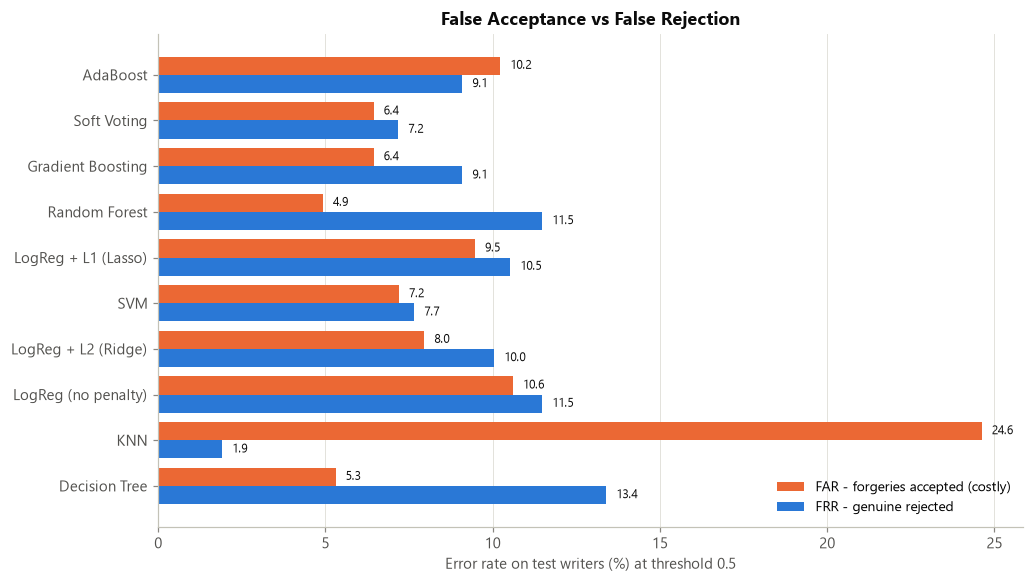

In [28]:
fig, ax = plt.subplots(figsize=(9.5, 5.4))
yy = np.arange(len(order))
tb = test_B.set_index("Model").loc[ylab]
ax.barh(yy + 0.2, tb.FAR * 100, height=0.4, color=P.FORGED, label="FAR - forgeries accepted (costly)")
ax.barh(yy - 0.2, tb.FRR * 100, height=0.4, color=P.GENUINE, label="FRR - genuine rejected")
for i, (a, r) in enumerate(zip(tb.FAR * 100, tb.FRR * 100)):
    ax.text(a + 0.3, i + 0.2, f"{a:.1f}", va="center", fontsize=8, color=P.INK)
    ax.text(r + 0.3, i - 0.2, f"{r:.1f}", va="center", fontsize=8, color=P.INK)
ax.set_yticks(yy, ylab)
ax.set_xlabel("Error rate on test writers (%) at threshold 0.5")
ax.set_title("False Acceptance vs False Rejection")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
P.save(fig, "fig16_far_frr")
plt.show()

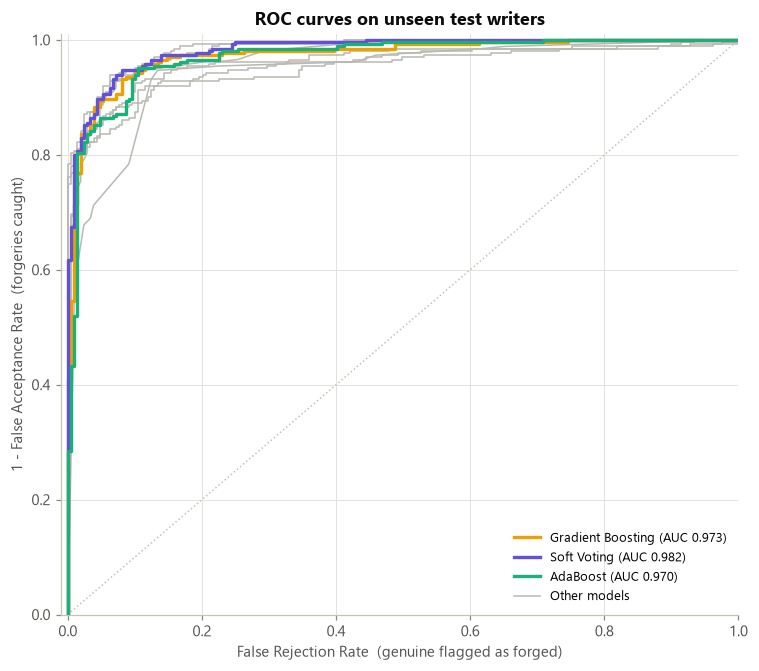

In [29]:
fig, ax = plt.subplots(figsize=(7, 6.2))
highlight = order[:3]
for name in order[::-1]:
    s = get_scores(final_B[name], X_te)
    fpr, tpr, _ = roc_curve(y_te, s)
    auc = test_B.set_index("Model").loc[name, "ROC_AUC"]
    if name in highlight:
        ax.plot(fpr, tpr, color=P.TRIO[highlight.index(name)], lw=2.2, label=f"{name} (AUC {auc:.3f})", zorder=3)
    else:
        ax.plot(fpr, tpr, color=P.NEUTRAL, lw=1, zorder=2)
ax.plot([], [], color=P.NEUTRAL, lw=1, label="Other models")
ax.plot([0, 1], [0, 1], color=P.AXIS, ls=":", lw=1)
ax.set(xlabel="False Rejection Rate  (genuine flagged as forged)",
       ylabel="1 - False Acceptance Rate  (forgeries caught)",
       title="ROC curves on unseen test writers")
ax.legend(loc="lower right", fontsize=8.5)
ax.set_xlim(-0.01, 1); ax.set_ylim(0, 1.01)
fig.tight_layout()
P.save(fig, "fig17_roc_curves")
plt.show()

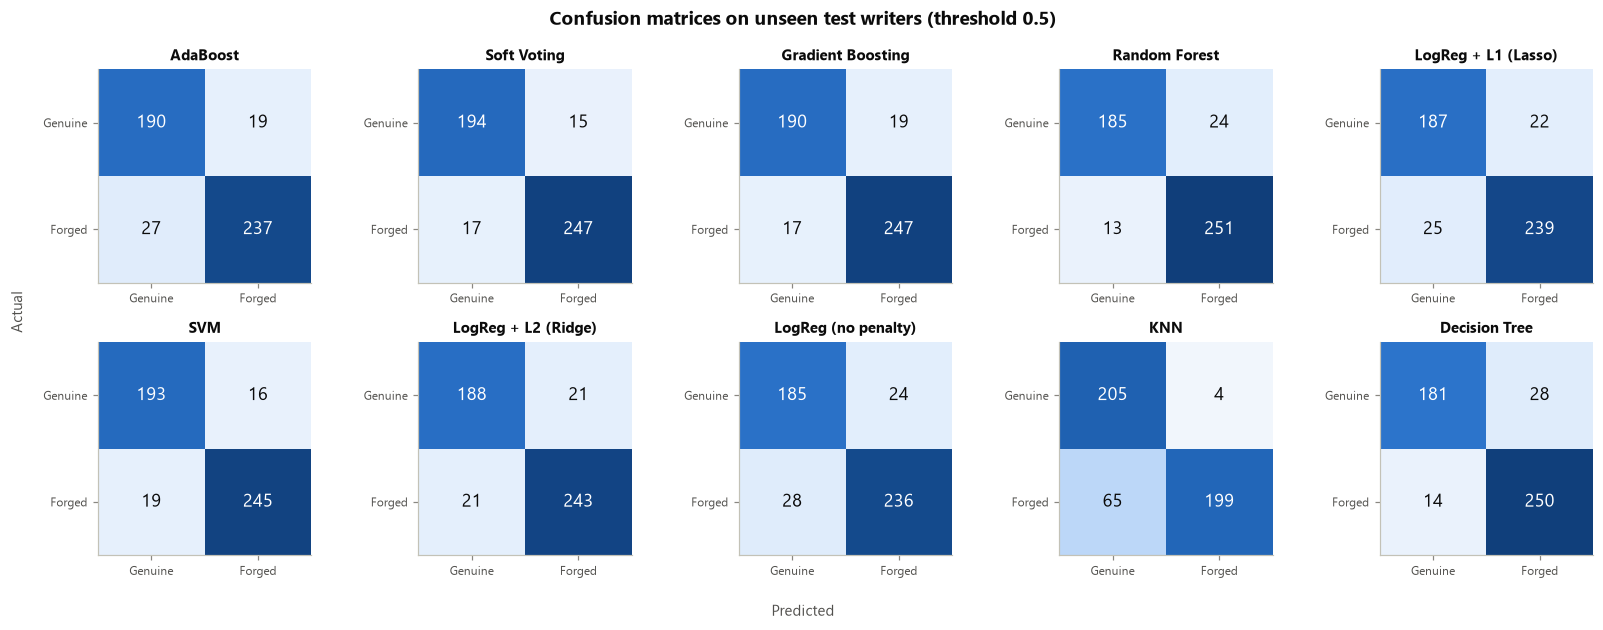

In [30]:
n = len(order)
cols = 5
rows_ = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(3.0 * cols, 2.85 * rows_))
for ax, name in zip(axes.ravel(), order):
    pred = (get_scores(final_B[name], X_te) >= 0.5).astype(int)
    cm = confusion_matrix(y_te, pred, labels=[0, 1])
    ax.imshow(cm, cmap=P.SEQUENTIAL, vmin=0, vmax=cm.sum(axis=1).max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.sum(axis=1).max() * 0.55 else P.INK)
    ax.set_xticks([0, 1], ["Genuine", "Forged"], fontsize=8)
    ax.set_yticks([0, 1], ["Genuine", "Forged"], fontsize=8)
    ax.set_title(name, fontsize=9.5)
    ax.grid(False)
for ax in axes.ravel()[n:]:
    ax.axis("off")
fig.supxlabel("Predicted", fontsize=10, color=P.INK_2)
fig.supylabel("Actual", fontsize=10, color=P.INK_2)
fig.suptitle("Confusion matrices on unseen test writers (threshold 0.5)", fontsize=12.5, fontweight="bold",
             color=P.INK)
fig.tight_layout()
P.save(fig, "fig18_confusion_matrices")
plt.show()

### Experiment 1 vs Experiment 2

,Experiment,Best model (by CV),Accuracy,Precision,Recall,F1,ROC_AUC,FAR,FRR,EER
0,Exp. 1: absolute features,Gradient Boosting,0.7421,0.7261,0.8636,0.7889,0.8306,0.1364,0.4115,0.2432
1,Exp. 2: writer-normalised,AdaBoost,0.9027,0.9258,0.8977,0.9115,0.9700,0.1023,0.0909,0.0990


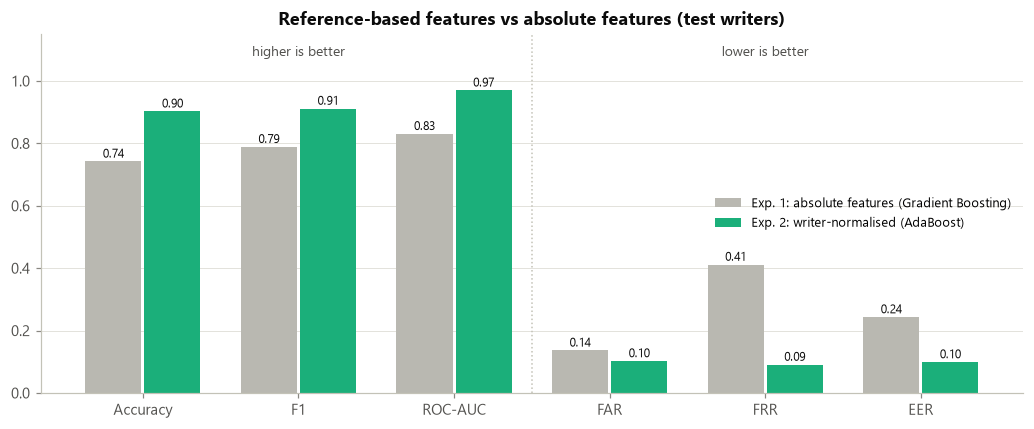

In [31]:
best_A = cv_A.sort_values("CV roc_auc", ascending=False)["Model"].iloc[0]
cmp_rows = []
for exp, name, tbl in (("Exp. 1: absolute features", best_A, test_A.set_index("Model")),
                       ("Exp. 2: writer-normalised", best_name, test_B.set_index("Model"))):
    r = tbl.loc[name]
    cmp_rows.append({"Experiment": exp, "Best model (by CV)": name, **{k: r[k] for k in
                     ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "FAR", "FRR", "EER"]}})
cmp = pd.DataFrame(cmp_rows)
cmp.to_csv(config.TABLE_DIR / "experiment_comparison.csv", index=False)
display(cmp.round(4))

fig, ax = plt.subplots(figsize=(9.5, 4))
metrics_ = ["Accuracy", "F1", "ROC_AUC", "FAR", "FRR", "EER"]
xx = np.arange(len(metrics_))
for k, ((_, row_), color) in enumerate(zip(cmp.iterrows(), [P.NEUTRAL, P.TRIO[0]])):
    vals = [row_[m] for m in metrics_]
    ax.bar(xx + (k - 0.5) * 0.38, vals, width=0.36, color=color,
           label=f"{row_['Experiment']} ({row_['Best model (by CV)']})")
    for xv, v in zip(xx + (k - 0.5) * 0.38, vals):
        ax.text(xv, v + 0.012, f"{v:.2f}", ha="center", fontsize=8, color=P.INK)
ax.set_xticks(xx, ["Accuracy", "F1", "ROC-AUC", "FAR", "FRR", "EER"])
ax.axvline(2.5, color=P.AXIS, lw=1, ls=":")
ax.text(1.0, 1.08, "higher is better", ha="center", color=P.INK_2, fontsize=9)
ax.text(4.0, 1.08, "lower is better", ha="center", color=P.INK_2, fontsize=9)
ax.set_ylim(0, 1.15)
ax.set_title("Reference-based features vs absolute features (test writers)")
ax.legend(loc="center right", fontsize=8.5)
ax.grid(axis="x", visible=False)
fig.tight_layout()
P.save(fig, "fig19_experiment_comparison")
plt.show()

## 12. Choosing the decision threshold for a low False Acceptance Rate
A forged signature that is accepted (FAR) means fraud goes through, so it is the costliest error.
The default threshold 0.5 treats both errors equally. We choose thresholds on the **training writers'
out-of-fold predictions** (never on the test set) and then apply them to the unseen test writers:
* **EER threshold** - where FAR = FRR on the training CV predictions;
* **High-security threshold** - the largest threshold whose training-CV FAR is at most 5 %.

AdaBoost: training-CV EER = 0.0840


,Operating point,Threshold,Accuracy,FAR,FRR,Recall (forged),Precision
0,Default,0.5000,0.9027,0.1023,0.0909,0.8977,0.9258
1,EER (FAR = FRR on train CV),0.5122,0.8985,0.1136,0.0861,0.8864,0.9286
2,High security (train-CV FAR <= 5%),0.4555,0.9197,0.0492,0.1196,0.9508,0.9094


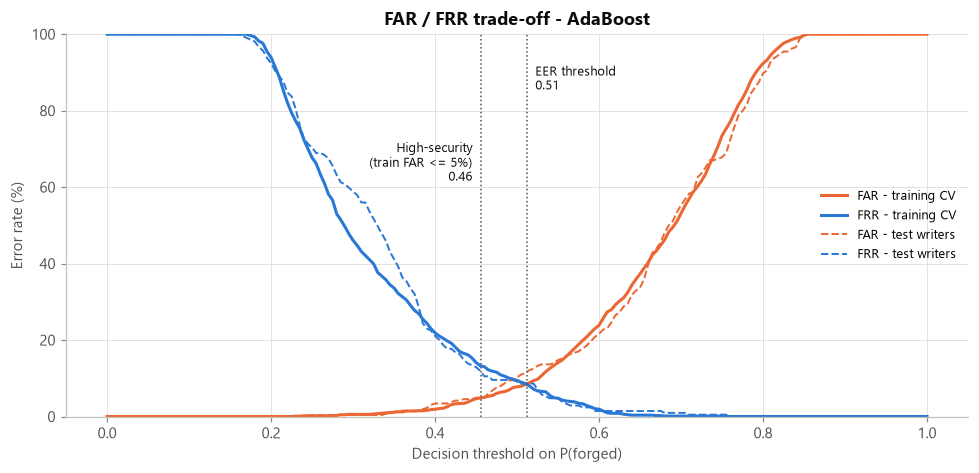

In [32]:
best_model = final_B[best_name]
oof = cv_scores_for(best_model, X_tr, y_tr, g_tr)
eer_tr, thr_eer = equal_error_rate(y_tr, oof)
thr_sec = threshold_for_far(y_tr, oof, target_far=0.05)
s_te = get_scores(best_model, X_te)

thr_rows = []
for label, t in (("Default", 0.5), ("EER (FAR = FRR on train CV)", thr_eer), ("High security (train-CV FAR <= 5%)", thr_sec)):
    m = compute_metrics(y_te, s_te, t)
    thr_rows.append({"Operating point": label, "Threshold": t, "Accuracy": m["Accuracy"],
                     "FAR": m["FAR"], "FRR": m["FRR"], "Recall (forged)": m["Recall"], "Precision": m["Precision"]})
thr_tbl = pd.DataFrame(thr_rows)
thr_tbl.to_csv(config.TABLE_DIR / "threshold_results.csv", index=False)
print(f"{best_name}: training-CV EER = {eer_tr:.4f}")
display(thr_tbl.round(4))

ts = np.linspace(0, 1, 201)
far_c = [far_frr(y_tr, (oof >= t).astype(int))[0] for t in ts]
frr_c = [far_frr(y_tr, (oof >= t).astype(int))[1] for t in ts]
far_t = [far_frr(y_te, (s_te >= t).astype(int))[0] for t in ts]
frr_t = [far_frr(y_te, (s_te >= t).astype(int))[1] for t in ts]
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(ts, np.array(far_c) * 100, color=P.FORGED, label="FAR - training CV")
ax.plot(ts, np.array(frr_c) * 100, color=P.GENUINE, label="FRR - training CV")
ax.plot(ts, np.array(far_t) * 100, color=P.FORGED, ls="--", lw=1.3, label="FAR - test writers")
ax.plot(ts, np.array(frr_t) * 100, color=P.GENUINE, ls="--", lw=1.3, label="FRR - test writers")
for t, lab, yy, ha, dx in ((thr_eer, "EER threshold", 92, "left", 0.01),
                           (thr_sec, "High-security\n(train FAR <= 5%)", 72, "right", -0.01)):
    ax.axvline(t, color=P.INK_2, ls=":", lw=1)
    ax.text(t + dx, yy, f"{lab}\n{t:.2f}", fontsize=8.5, color=P.INK, ha=ha, va="top")
ax.set(xlabel="Decision threshold on P(forged)", ylabel="Error rate (%)",
       title=f"FAR / FRR trade-off - {best_name}")
ax.set_ylim(0, 100)
ax.legend(fontsize=8.5, loc="center right")
fig.tight_layout()
P.save(fig, "fig20_threshold_analysis")
plt.show()

**Interpretation.** With the high-security threshold chosen on training data only, the FAR of AdaBoost on the
unseen writers drops to **4.9%** (FRR 12.0%, accuracy 92.0%): fewer forgeries
are accepted, and slightly more genuine signatures are sent for a manual check.

## 13. Interpretation
### 13.1 Which features does the best model rely on? (permutation importance on the test writers)
Permutation importance shuffles one feature at a time and measures how much the ROC-AUC drops. It works
for any model, and because it is computed on unseen writers it shows what really generalises.

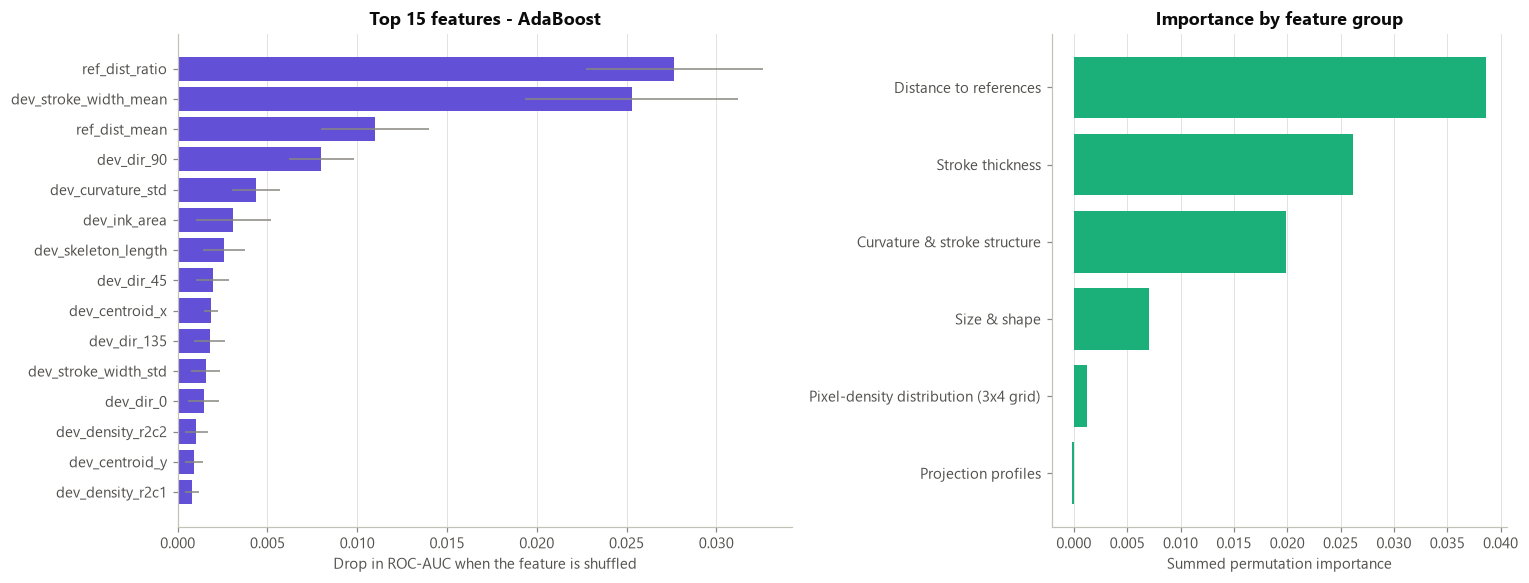

In [33]:
pi = permutation_importance(best_model, X_te, y_te, scoring="roc_auc", n_repeats=15,
                            random_state=config.RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std}, index=kept_B)
imp = imp.sort_values("importance", ascending=False)
imp.to_csv(config.TABLE_DIR / "permutation_importance.csv")

group_of = {f"dev_{f}": g.replace(" & pressure", "") for g, fs in FEATURE_GROUPS.items() for f in fs}
group_of.update({f: "Distance to references" for f in DIST_FEATURES})
grp_imp = imp.assign(group=[group_of[f] for f in imp.index]).groupby("group")["importance"].sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.35, 1]})
t15 = imp.head(15).iloc[::-1]
axes[0].barh(t15.index, t15.importance, xerr=t15["std"], color=P.MAIN, error_kw={"ecolor": P.MUTED, "lw": 1})
axes[0].set(xlabel="Drop in ROC-AUC when the feature is shuffled", title=f"Top 15 features - {best_name}")
axes[0].grid(axis="y", visible=False)
axes[1].barh(grp_imp.index, grp_imp.values, color=P.TRIO[0])
axes[1].set(xlabel="Summed permutation importance", title="Importance by feature group")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
P.save(fig, "fig21_feature_importance")
plt.show()

### 13.2 How many reference signatures are needed?
The best model (same hyper-parameters) is re-trained with 1-12 references per writer.

,References per writer,Questioned test signatures,Accuracy,ROC_AUC,EER
0,1,517,0.8414,0.9345,0.1625
1,2,506,0.8972,0.9649,0.0968
2,3,495,0.8990,0.9605,0.1031
3,5,473,0.9027,0.9700,0.0990
4,8,440,0.9364,0.9885,0.0653
5,10,418,0.9330,0.9798,0.0666
6,12,396,0.9217,0.9790,0.0795


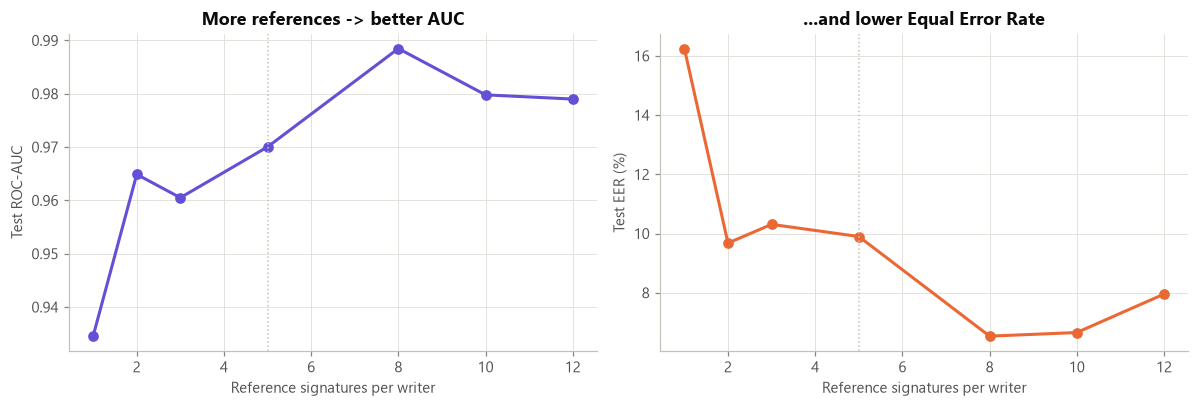

In [34]:
k_rows = []
for k in [1, 2, 3, 5, 8, 10, 12]:
    is_ref_k = select_references(records, k, config.RANDOM_STATE)
    m_k = is_ref_k & records.writer.isin(train_writers)
    scale_k = pooled_within_writer_std(records.loc[m_k, F], records.loc[m_k, "writer"]) if k > 1 else scale
    ds_k = build_reference_dataset(records, F, is_ref_k, scale_k)
    tr_k = ds_k.writer.isin(train_writers).to_numpy()
    mdl = clone(best_model).fit(ds_k.loc[tr_k, kept_B], ds_k.loc[tr_k, "label"])
    sk = get_scores(mdl, ds_k.loc[~tr_k, kept_B])
    mk = compute_metrics(ds_k.loc[~tr_k, "label"], sk)
    k_rows.append({"References per writer": k, "Questioned test signatures": int((~tr_k).sum()),
                   "Accuracy": mk["Accuracy"], "ROC_AUC": mk["ROC_AUC"], "EER": mk["EER"]})
k_tbl = pd.DataFrame(k_rows)
k_tbl.to_csv(config.TABLE_DIR / "effect_of_references.csv", index=False)
display(k_tbl.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(k_tbl["References per writer"], k_tbl.ROC_AUC, "-o", color=P.MAIN)
axes[0].set(xlabel="Reference signatures per writer", ylabel="Test ROC-AUC", title="More references -> better AUC")
axes[1].plot(k_tbl["References per writer"], k_tbl.EER * 100, "-o", color=P.FORGED)
axes[1].set(xlabel="Reference signatures per writer", ylabel="Test EER (%)", title="...and lower Equal Error Rate")
for ax in axes:
    ax.axvline(config.N_REFERENCES, color=P.AXIS, ls=":", lw=1)
fig.tight_layout()
P.save(fig, "fig22_effect_of_references")
plt.show()

### 13.3 Where does the model fail? (per-writer analysis and error examples)

,writer,accuracy,FAR,FRR
0,6,0.9070,0.1250,0.0530
1,13,0.9530,0.0000,0.1050
2,14,0.8140,0.0000,0.4210
3,20,1.0000,0.0000,0.0000
4,27,0.6980,0.5000,0.0530
5,32,0.9530,0.0420,0.0530
6,33,0.9530,0.0420,0.0530
7,42,0.9530,0.0000,0.1050
8,44,0.7670,0.3750,0.0530
9,50,0.9530,0.0420,0.0530


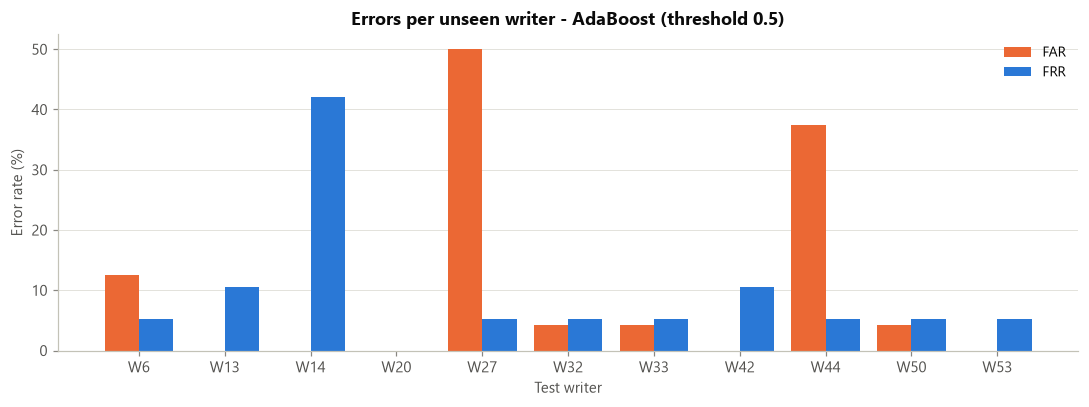

In [35]:
pred_te = (s_te >= 0.5).astype(int)
te_info = refset.loc[is_test, ["file", "writer", "label", "row_id"]].reset_index(drop=True)
te_info["score"] = s_te
te_info["pred"] = pred_te
pw = []
for wr, g in te_info.groupby("writer"):
    far_w, frr_w = far_frr(g.label, g.pred)
    pw.append({"writer": wr, "accuracy": (g.label == g.pred).mean(), "FAR": far_w, "FRR": frr_w})
pw = pd.DataFrame(pw)
pw.to_csv(config.TABLE_DIR / "per_writer_results.csv", index=False)
display(pw.round(3))

fig, ax = plt.subplots(figsize=(10, 3.8))
xx = np.arange(len(pw))
ax.bar(xx - 0.2, pw.FAR * 100, width=0.4, color=P.FORGED, label="FAR")
ax.bar(xx + 0.2, pw.FRR * 100, width=0.4, color=P.GENUINE, label="FRR")
ax.set_xticks(xx, [f"W{w}" for w in pw.writer])
ax.set(ylabel="Error rate (%)", xlabel="Test writer", title=f"Errors per unseen writer - {best_name} (threshold 0.5)")
ax.legend()
ax.grid(axis="x", visible=False)
fig.tight_layout()
P.save(fig, "fig23_per_writer_errors")
plt.show()

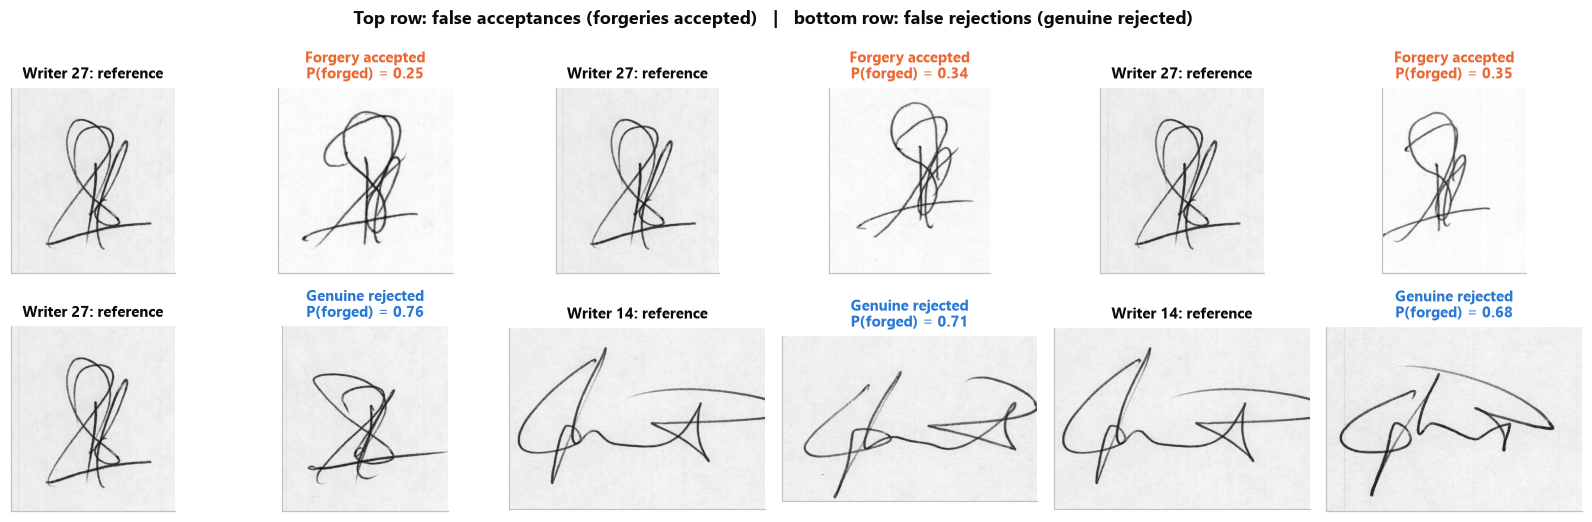

In [36]:
fa = te_info[(te_info.label == 1) & (te_info.pred == 0)].sort_values("score").head(3)
fr = te_info[(te_info.label == 0) & (te_info.pred == 1)].sort_values("score", ascending=False).head(3)
cases = [("Forgery accepted", r) for _, r in fa.iterrows()] + \
        [("Genuine rejected", r) for _, r in fr.iterrows()]
if cases:
    fig, axes = plt.subplots(2, 6, figsize=(15, 4.8))
    for ax in axes.ravel():
        ax.axis("off")
    slots = [(0, k) for k in range(len(fa))] + [(1, k) for k in range(len(fr))]
    for (title, r), (row_i, k) in zip(cases, slots):
        a0, a1 = axes[row_i, 2 * k], axes[row_i, 2 * k + 1]
        ref_row = records[is_ref & (records.writer == r.writer)].iloc[0]
        q_row = records.loc[r.row_id]
        a0.imshow(load_gray(ref_row.path), cmap="gray")
        a0.set_title(f"Writer {r.writer}: reference", fontsize=9.5, color=P.INK)
        a1.imshow(load_gray(q_row.path), cmap="gray")
        a1.set_title(f"{title}\nP(forged) = {r.score:.2f}", fontsize=9.5,
                     color=P.FORGED if r.label == 1 else P.GENUINE)
        for a in (a0, a1):
            a.axis("on"); a.set_xticks([]); a.set_yticks([]); a.grid(False)
            for s in a.spines.values():
                s.set_color(P.AXIS)
    fig.suptitle("Top row: false acceptances (forgeries accepted)   |   bottom row: false rejections "
                 "(genuine rejected)", fontsize=11.5, fontweight="bold", color=P.INK)
    fig.tight_layout()
    P.save(fig, "fig24_error_examples")
    plt.show()
else:
    print("No misclassified test signatures at threshold 0.5.")

## 14. Save the final model for the demo application
The saved bundle contains everything the Streamlit app needs to verify a new signature:
the fitted pipeline, the selected feature list, the pooled scale vector, the thresholds and the test metrics.

In [37]:
bundle = {
    "model": best_model,
    "model_name": best_name,
    "raw_features": F,
    "selected_features": kept_B,
    "scale": scale,
    "n_references": config.N_REFERENCES,
    "thresholds": {"default": 0.5, "eer": float(thr_eer), "high_security": float(thr_sec)},
    "test_metrics": test_B.set_index("Model").loc[best_name].to_dict(),
    "cv_auc": float(cv_B.set_index("Model").loc[best_name, "CV roc_auc"]),
    "train_writers": train_writers,
    "test_writers": test_writers,
    "versions": {"sklearn": sklearn.__version__, "skimage": skimage.__version__},
}
joblib.dump(bundle, config.MODEL_DIR / "signature_verifier.joblib", compress=3)
with open(config.MODEL_DIR / "model_card.json", "w") as fh:
    json.dump({k: v for k, v in bundle.items() if k not in ("model", "scale")}, fh, indent=2, default=float)
print("Saved:", config.MODEL_DIR / "signature_verifier.joblib")

# sample signatures of 4 UNSEEN test writers for the live demo
sample_dir = ROOT / "app" / "samples"
shutil.rmtree(sample_dir, ignore_errors=True)    # files are re-copied below (overwritten if still present)
for wr in test_writers[:4]:
    rows_w = records[records.writer == wr]
    refs = rows_w[is_ref.loc[rows_w.index]]
    q_gen = rows_w[(rows_w.label == 0) & ~is_ref.loc[rows_w.index]].head(5)
    q_for = rows_w[rows_w.label == 1].head(5)
    for sub, part in (("references", refs), ("questioned", pd.concat([q_gen, q_for]))):
        d = sample_dir / f"writer_{wr:02d}" / sub
        d.mkdir(parents=True, exist_ok=True)
        for _, r in part.iterrows():
            shutil.copy(r.path, d / r.file)
print("Demo samples copied to", sample_dir)

Saved: C:\Users\nancy\OneDrive\Desktop\ML_Project\models\signature_verifier.joblib


Demo samples copied to C:\Users\nancy\OneDrive\Desktop\ML_Project\app\samples


## 15. Summary
* **EDA** showed balanced classes and no missing / duplicate data, but three real data issues: varying image
  size and margins, scanner noise, and a **scan-brightness artefact that separates genuine from forged scans
  perfectly** (handled by intensity normalisation and by excluding grey-level features). Most importantly,
  **writer identity dominates the raw features**.
* **51 hand-crafted features** were derived (49 used by the models); turning them into **deviations from each
  writer's 5 reference signatures** made them far more discriminative.
* **Regularization:** L1 removes redundant features automatically, L2 stabilises correlated ones; pruning,
  C, K and learning-rate/estimators act as the regularizers of the other models.
* **Tuning:** GridSearchCV with writer-grouped 5-fold CV for every model.
* **Ensembles:** bagging (Random Forest), boosting (Gradient Boosting, AdaBoost) and soft voting were compared
  with single models.
* **Evaluation** on 11 writers never seen during training, with FAR / FRR / EER, and a threshold chosen on
  training data to keep the costly False Acceptance Rate low.

In [38]:
print("Best model:", best_name)
display(test_B.set_index("Model").loc[[best_name]].round(4))
display(thr_tbl.round(4))

Best model: AdaBoost


,Accuracy,Precision,Recall,F1,ROC_AUC,FAR,FRR,EER,Predict time (ms)
Model,,,,,,,,,
AdaBoost,0.9027,0.9258,0.8977,0.9115,0.9700,0.1023,0.0909,0.0990,497.9644


,Operating point,Threshold,Accuracy,FAR,FRR,Recall (forged),Precision
0,Default,0.5000,0.9027,0.1023,0.0909,0.8977,0.9258
1,EER (FAR = FRR on train CV),0.5122,0.8985,0.1136,0.0861,0.8864,0.9286
2,High security (train-CV FAR <= 5%),0.4555,0.9197,0.0492,0.1196,0.9508,0.9094
